# Comparative Analysis of Bagging, Boosting, and Random Forests for Ensemble Prediction

**Team 15 — Machine Learning PBL-3**

This notebook independently compares Bagged Decision Trees, standard Gradient Boosting, and Random Forest on the UCI Debrecen Diabetic Retinopathy dataset. It is separate from PBL-1 and PBL-2. Results concern the dataset-defined label and are not clinical validation.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
from run_analysis import main as run_pipeline

run_pipeline()
RESULTS = ROOT / 'results'
EDA = ROOT / 'figures' / 'eda'
MODELS = ROOT / 'figures' / 'model_comparison'
print('PBL-3 root:', ROOT)
print('EDA figures:', len(list(EDA.glob('*.png'))), 'Model figures:', len(list(MODELS.glob('*.png'))))

{
  "source": "UCI Diabetic Retinopathy Debrecen data set",
  "source_url": "https://archive.ics.uci.edu/dataset/329/diabetic+retinopathy+debrecen",
  "access_date": "2026-11-16",
  "observations": 1151,
  "predictors": 18,
  "total_columns": 19,
  "missing_cells": 0,
  "duplicate_rows": 5,
  "class_0": 540,
  "class_1": 611,
  "class_ratio_positive_to_negative": 1.1314814814814815,
  "sha256": "f5b98c78ff4c82dfe1d48a0a1ea2724ec5c3f4ade7cfe3d3c44569daada7086c"
}

Selected hyperparameters:
 {
  "Bagging": {
    "parameters": {
      "estimator__max_depth": null,
      "estimator__min_samples_leaf": 3,
      "max_samples": 0.8,
      "n_estimators": 300
    },
    "training_cv_best_f1": 0.6848736783470162,
    "candidates": 24
  },
  "Gradient Boosting": {
    "parameters": {
      "learning_rate": 0.1,
      "max_depth": 2,
      "n_estimators": 200,
      "subsample": 0.8
    },
    "training_cv_best_f1": 0.7180951152257272,
    "candidates": 24
  },
  "Random Forest": {
    "parameter

## 1. Project Introduction

**Research question:** Which ensemble approach provides the most effective and reliable prediction of the Debrecen DR label under identical data, split, tuning, and evaluation conditions?

The comparison considers predictive quality, sensitivity, cross-validation stability, computational efficiency, and generalization—not accuracy alone.

In [2]:
summary = json.loads((RESULTS / 'dataset_summary.json').read_text())
display(pd.Series(summary, name='verified_value').to_frame())

,verified_value
source,UCI Diabetic Retinopathy Debrecen data set
source_url,https://archive.ics.uci.edu/dataset/329/diabet...
access_date,2026-11-16
observations,1151
predictors,18
total_columns,19
missing_cells,0
duplicate_rows,5
class_0,540
class_1,611


## 2. Dataset Loading

The preserved CSV is read from 'data/debrecen_dr.csv'. It contains image-derived tabular descriptors, not raw retinal photographs. The verified schema has 18 predictors plus one binary target.

In [3]:
from src.preprocessing import load_dataset, FEATURES
frame, X, y = load_dataset(ROOT / 'data' / 'debrecen_dr.csv')
print('Shape:', frame.shape)
display(frame.head())
print('Predictors:', len(FEATURES), '| Target values:', sorted(y.unique()))

Shape: (1151, 19)


,quality,pre_screening,ma1,ma2,ma3,ma4,ma5,ma6,exudate1,exudate2,exudate3,exudate5,exudate6,exudate7,exudate8,macula_opticdisc_distance,opticdisc_diameter,am_fm_classification,class
0,1,1,22,22,22,19,18,14,49.895756,17.775994,5.270920,0.018632,0.006864,0.003923,0.003923,0.486903,0.100025,1,0
1,1,1,24,24,22,18,16,13,57.709936,23.799994,3.325423,0.003903,0.003903,0.003903,0.003903,0.520908,0.144414,0,0
2,1,1,62,60,59,54,47,33,55.831441,27.993933,12.687485,1.393889,0.373252,0.041817,0.007744,0.530904,0.128548,0,1
3,1,1,55,53,53,50,43,31,40.467228,18.445954,9.118901,0.840261,0.272434,0.007653,0.001531,0.483284,0.114790,0,0
4,1,1,44,44,44,41,39,27,18.026254,8.570709,0.410381,0.000000,0.000000,0.000000,0.000000,0.475935,0.123572,0,1


Predictors: 18 | Target values: [np.int64(0), np.int64(1)]


## 3. Dataset Description

- 1,151 observations and 18 numerical predictors.
- Target 0: no signs of DR; target 1: signs of DR.
- No missing values; five exact duplicate rows.
- Class counts 540 versus 611: mild, not severe, imbalance.
- Detector outputs are not patient demographics or direct clinical measurements.

In [4]:
dictionary = pd.read_csv(RESULTS / 'feature_dictionary.csv')
display(dictionary)
display(pd.read_csv(RESULTS / 'descriptive_statistics.csv', index_col=0))

,feature,description,dtype,missing,unique_values,minimum,median,maximum
0,quality,Image-quality assessment indicator,int64,0,2,0.000000,1.000000,1.000000
1,pre_screening,Pre-screening abnormality indicator,int64,0,2,0.000000,1.000000,1.000000
2,ma1,Microaneurysm detector output at confidence le...,int64,0,110,1.000000,35.000000,151.000000
3,ma2,Microaneurysm detector output at confidence le...,int64,0,104,1.000000,35.000000,132.000000
4,ma3,Microaneurysm detector output at confidence le...,int64,0,99,1.000000,32.000000,120.000000
5,ma4,Microaneurysm detector output at confidence le...,int64,0,91,1.000000,29.000000,105.000000
6,ma5,Microaneurysm detector output at confidence le...,int64,0,84,1.000000,25.000000,97.000000
7,ma6,Microaneurysm detector output at confidence le...,int64,0,69,1.000000,18.000000,89.000000
8,exudate1,Normalized exudate detector output,float64,0,1141,0.349274,44.249119,403.939108
9,exudate2,Normalized exudate detector output,float64,0,1141,0.000000,17.038020,167.131427


,count,mean,std,min,25%,50%,75%,max
quality,1151.0,0.996525,0.058874,0.000000,1.000000,1.000000,1.000000,1.000000
pre_screening,1151.0,0.918332,0.273977,0.000000,1.000000,1.000000,1.000000,1.000000
ma1,1151.0,38.428323,25.620913,1.000000,16.000000,35.000000,55.000000,151.000000
ma2,1151.0,36.909644,24.105612,1.000000,16.000000,35.000000,53.000000,132.000000
ma3,1151.0,35.140747,22.805400,1.000000,15.000000,32.000000,51.000000,120.000000
ma4,1151.0,32.297133,21.114767,1.000000,14.000000,29.000000,48.000000,105.000000
ma5,1151.0,28.747176,19.509227,1.000000,11.000000,25.000000,43.000000,97.000000
ma6,1151.0,21.151173,15.101560,1.000000,8.000000,18.000000,32.000000,89.000000
exudate1,1151.0,64.096674,58.485289,0.349274,22.271597,44.249119,87.804112,403.939108
exudate2,1151.0,23.088012,21.602696,0.000000,7.939315,17.038020,31.305692,167.131427


## 4. Exploratory Data Analysis

EDA examines balance, distributions, correlation, missingness, target-linked differences, and IQR flags. Relationships are associations rather than clinical or causal evidence.

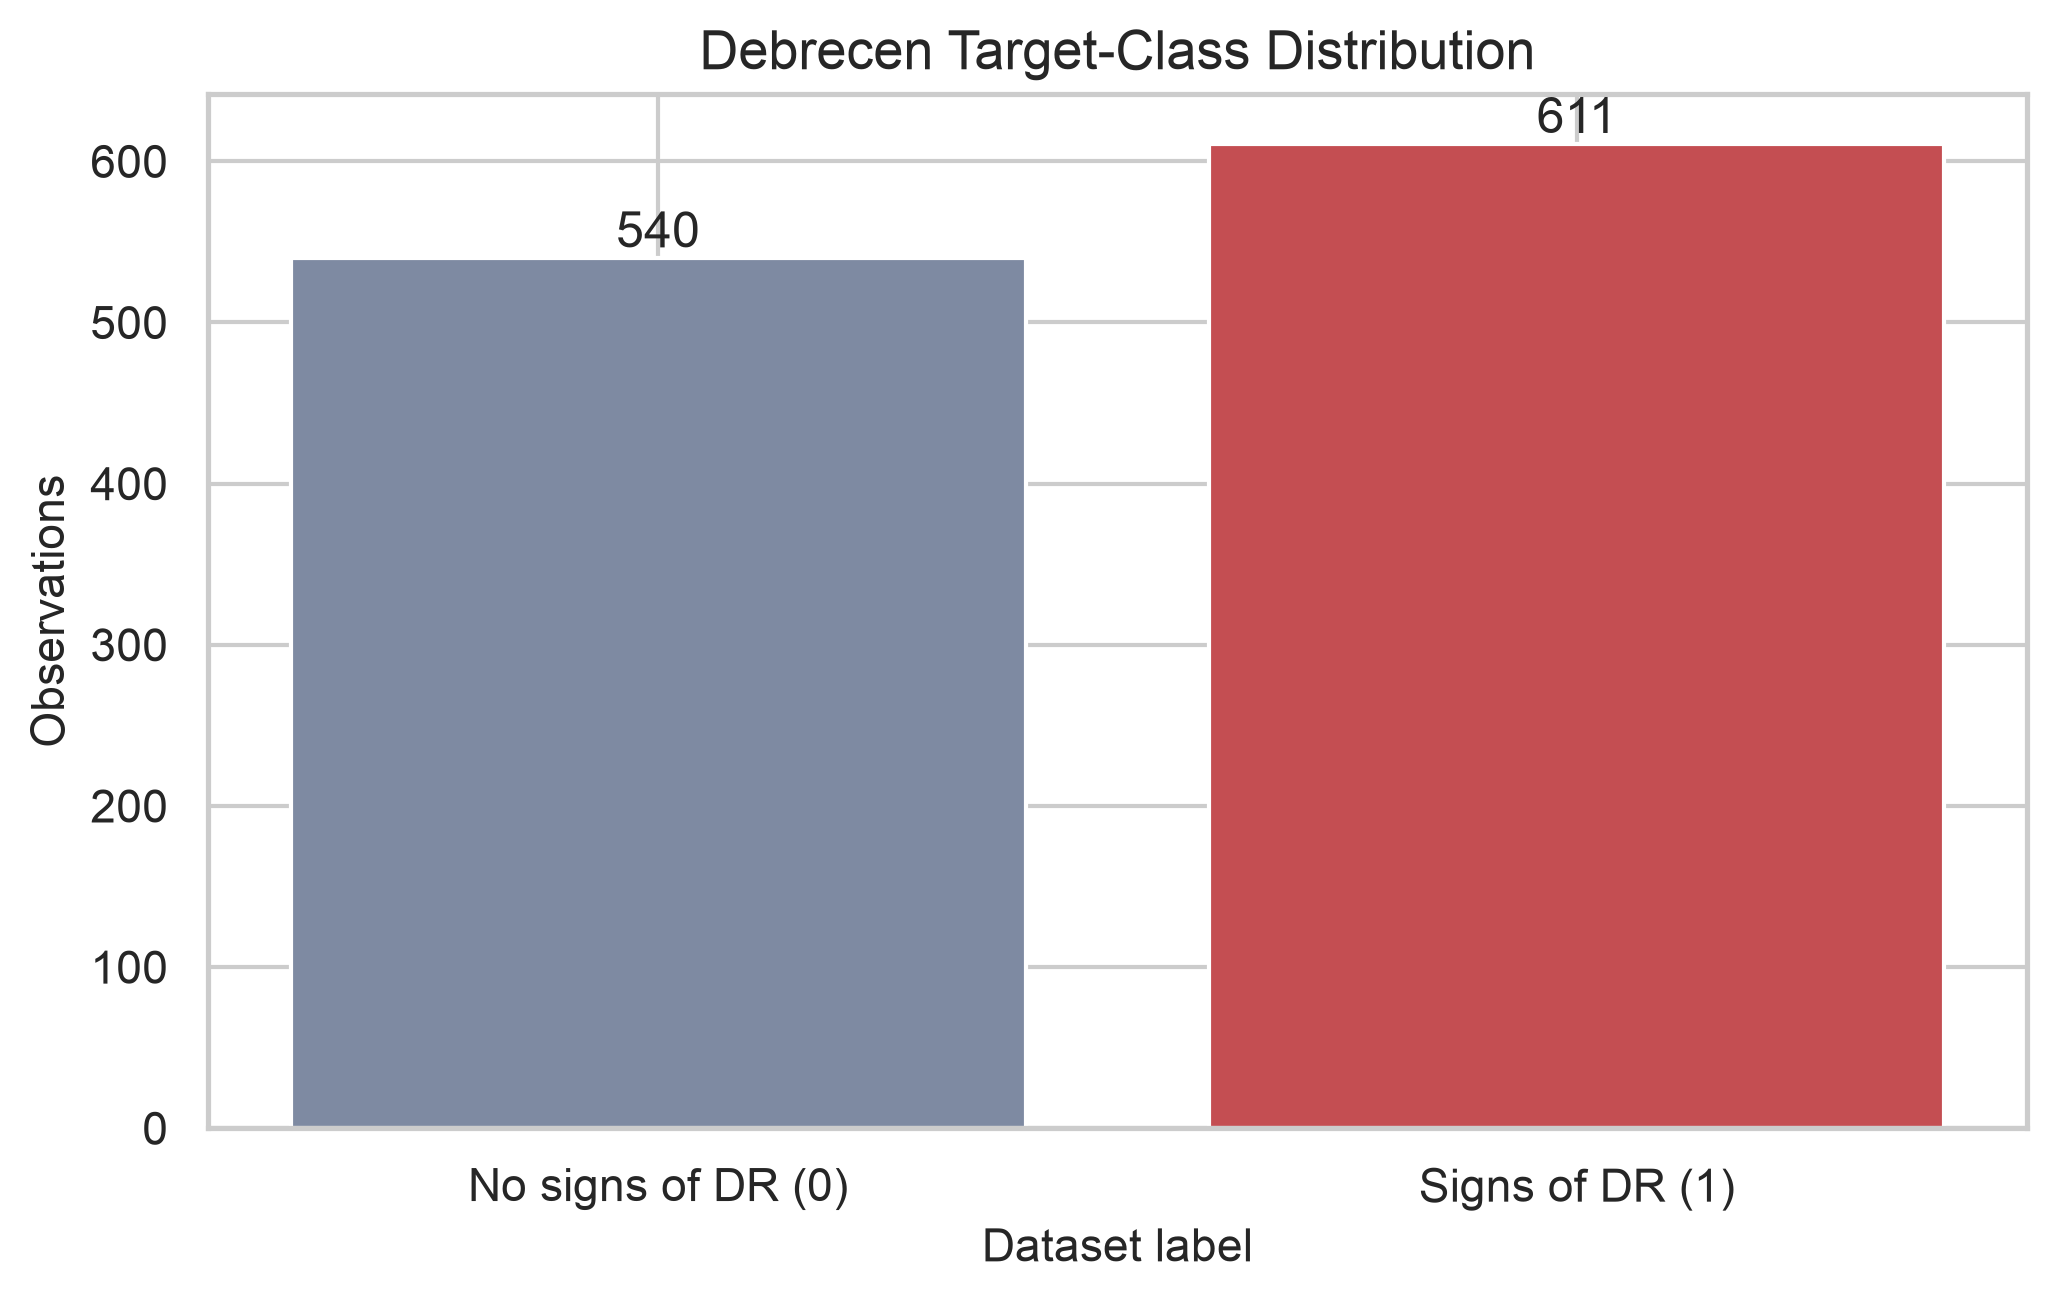

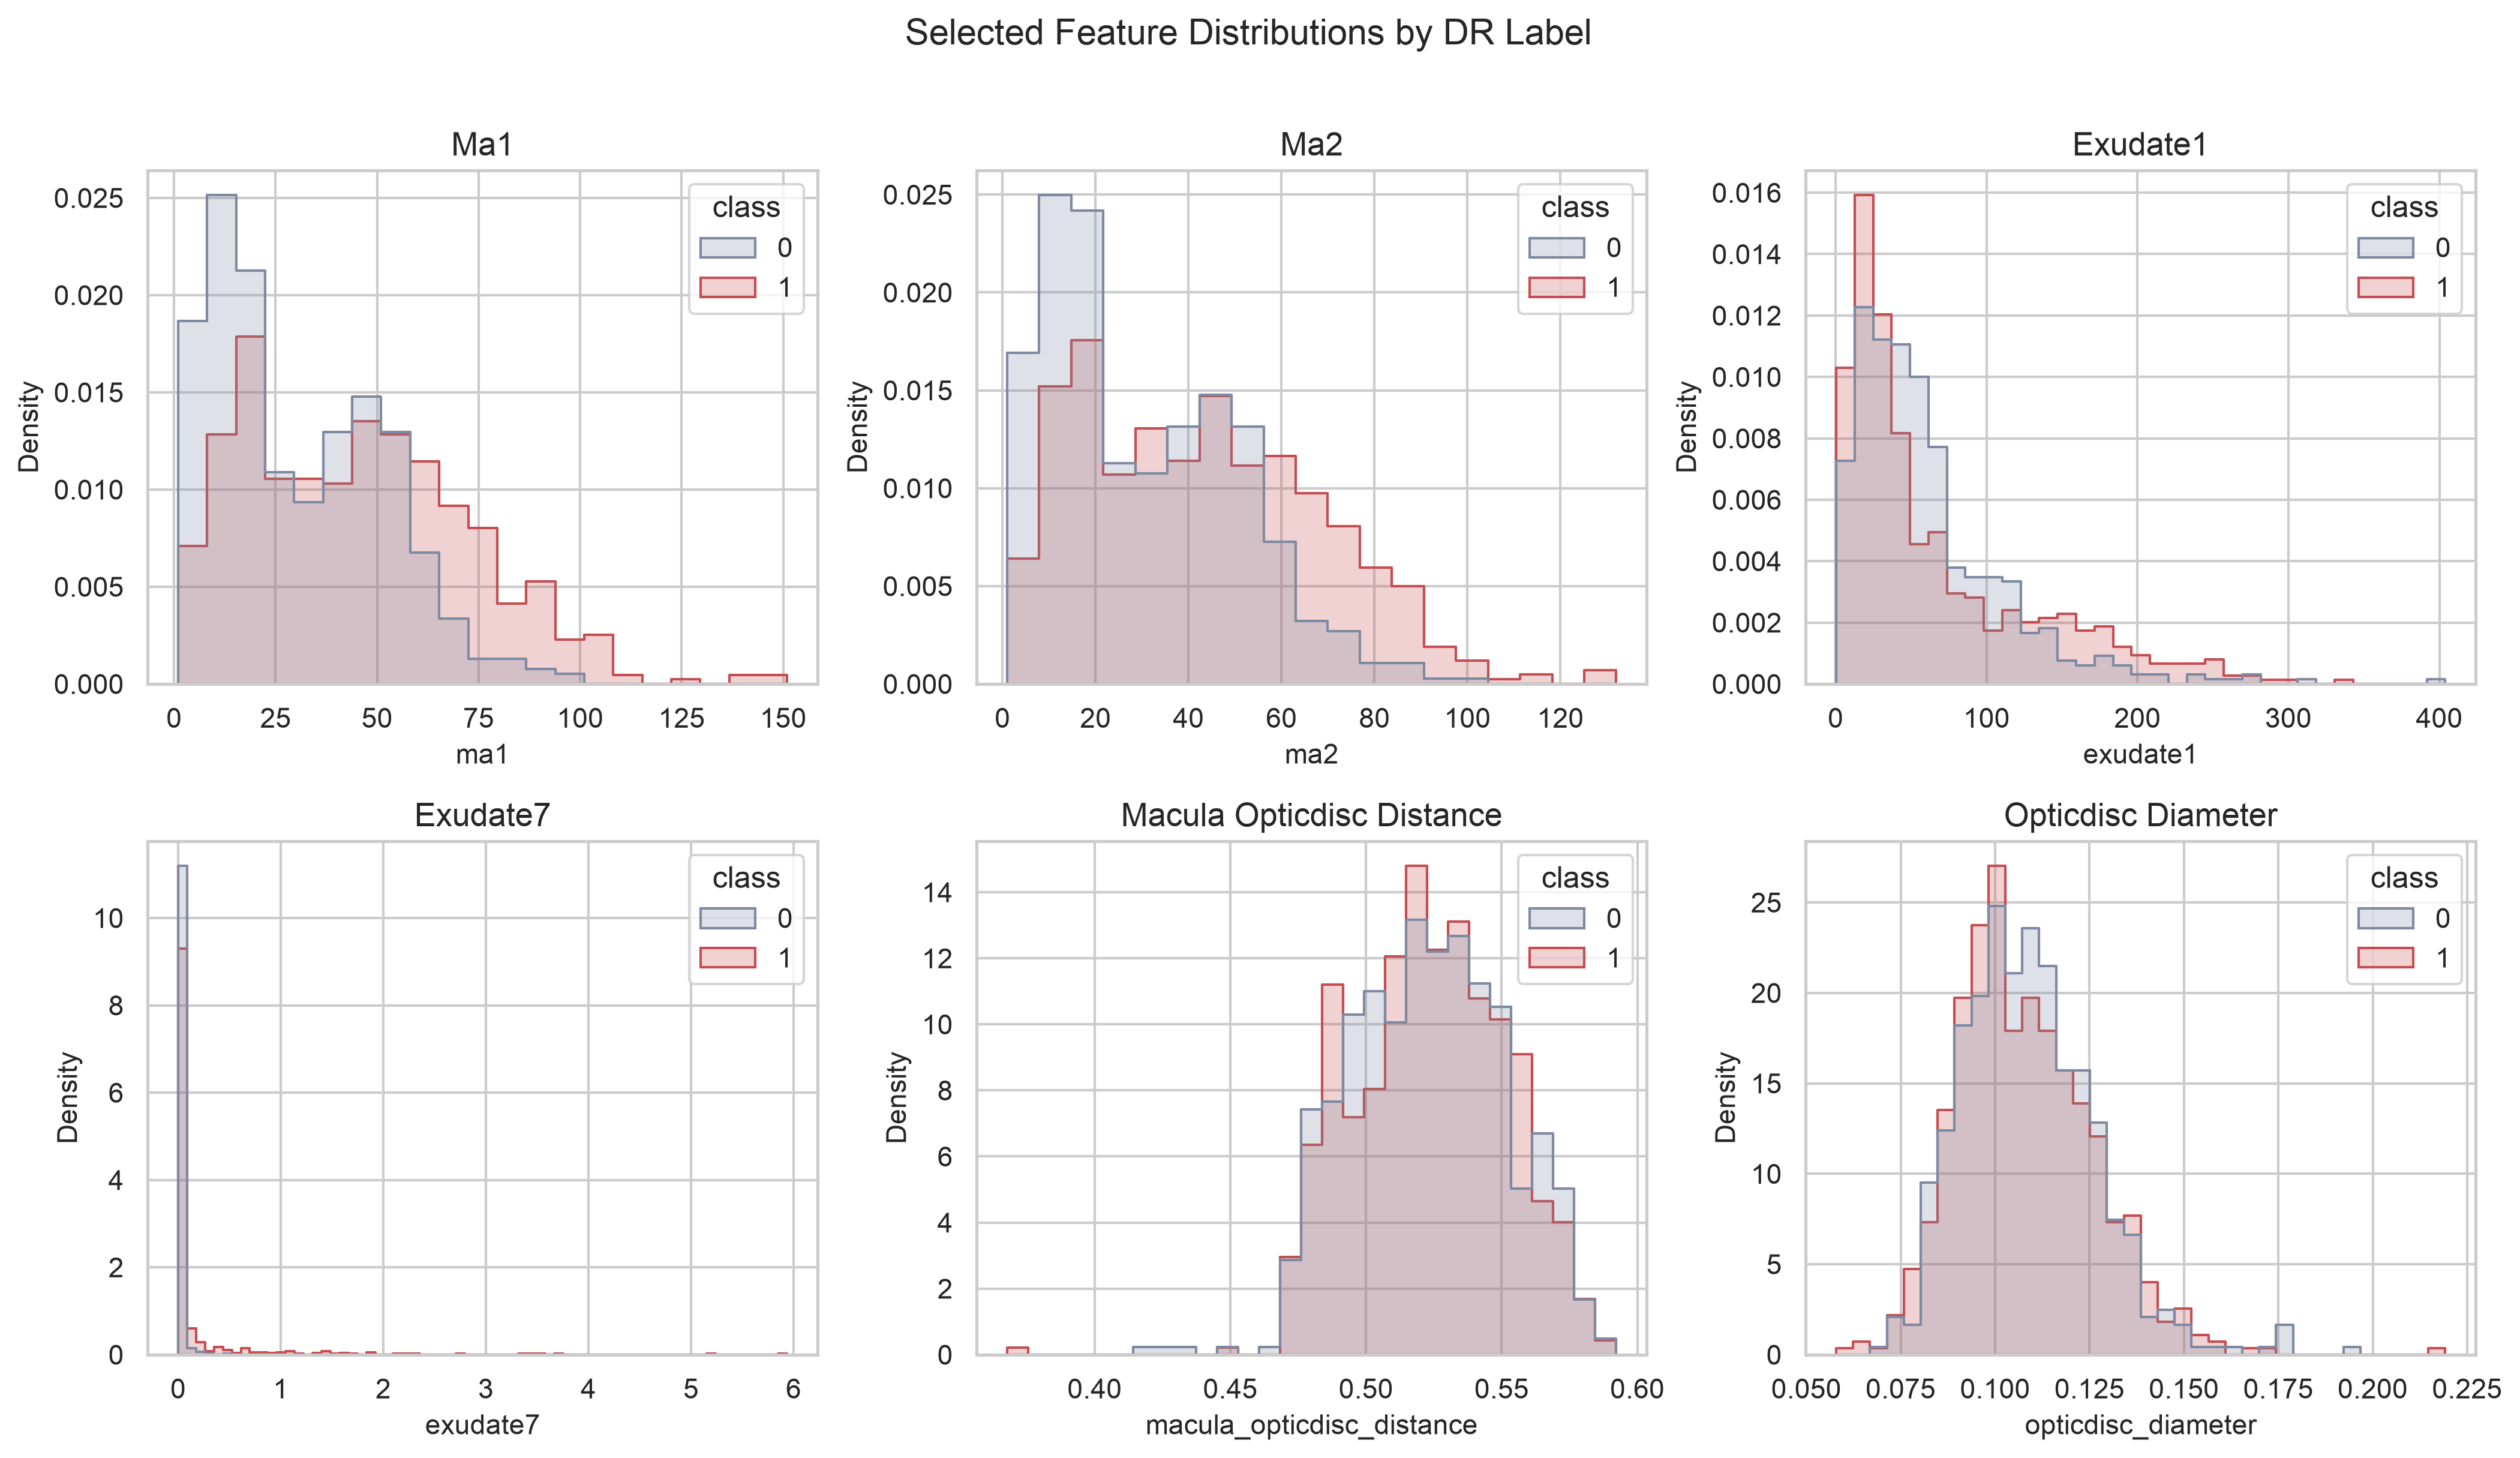

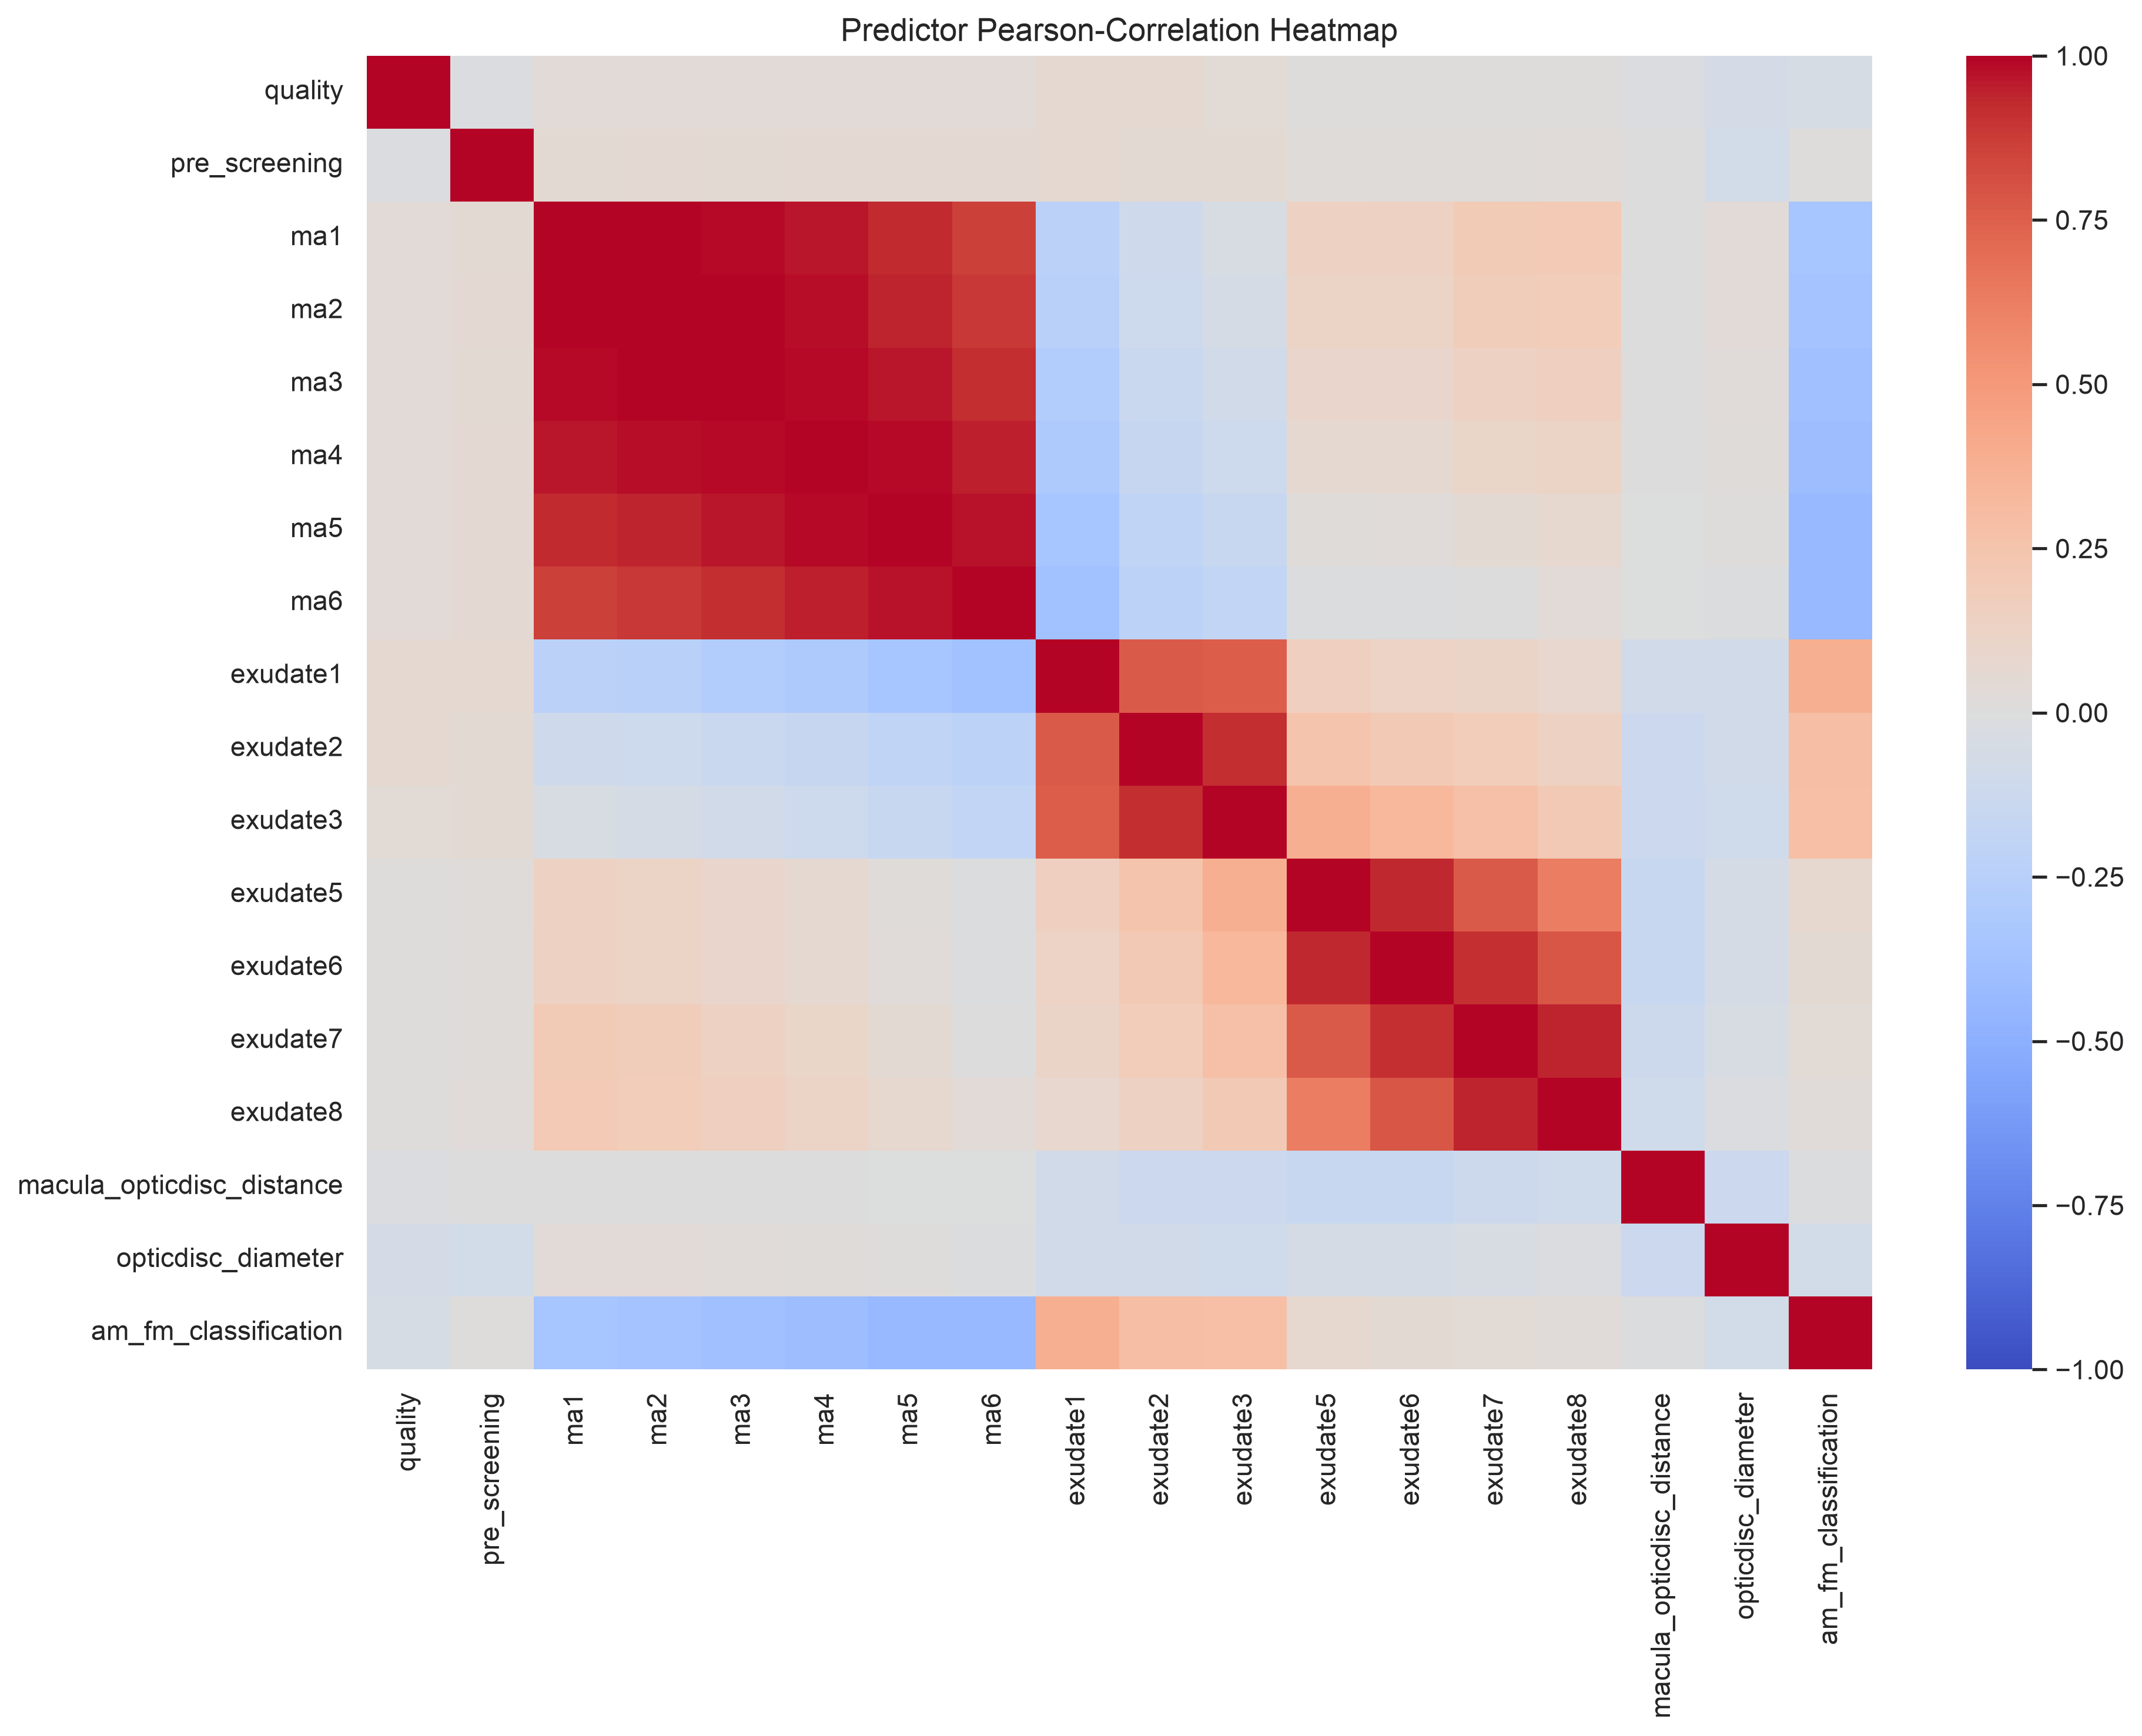

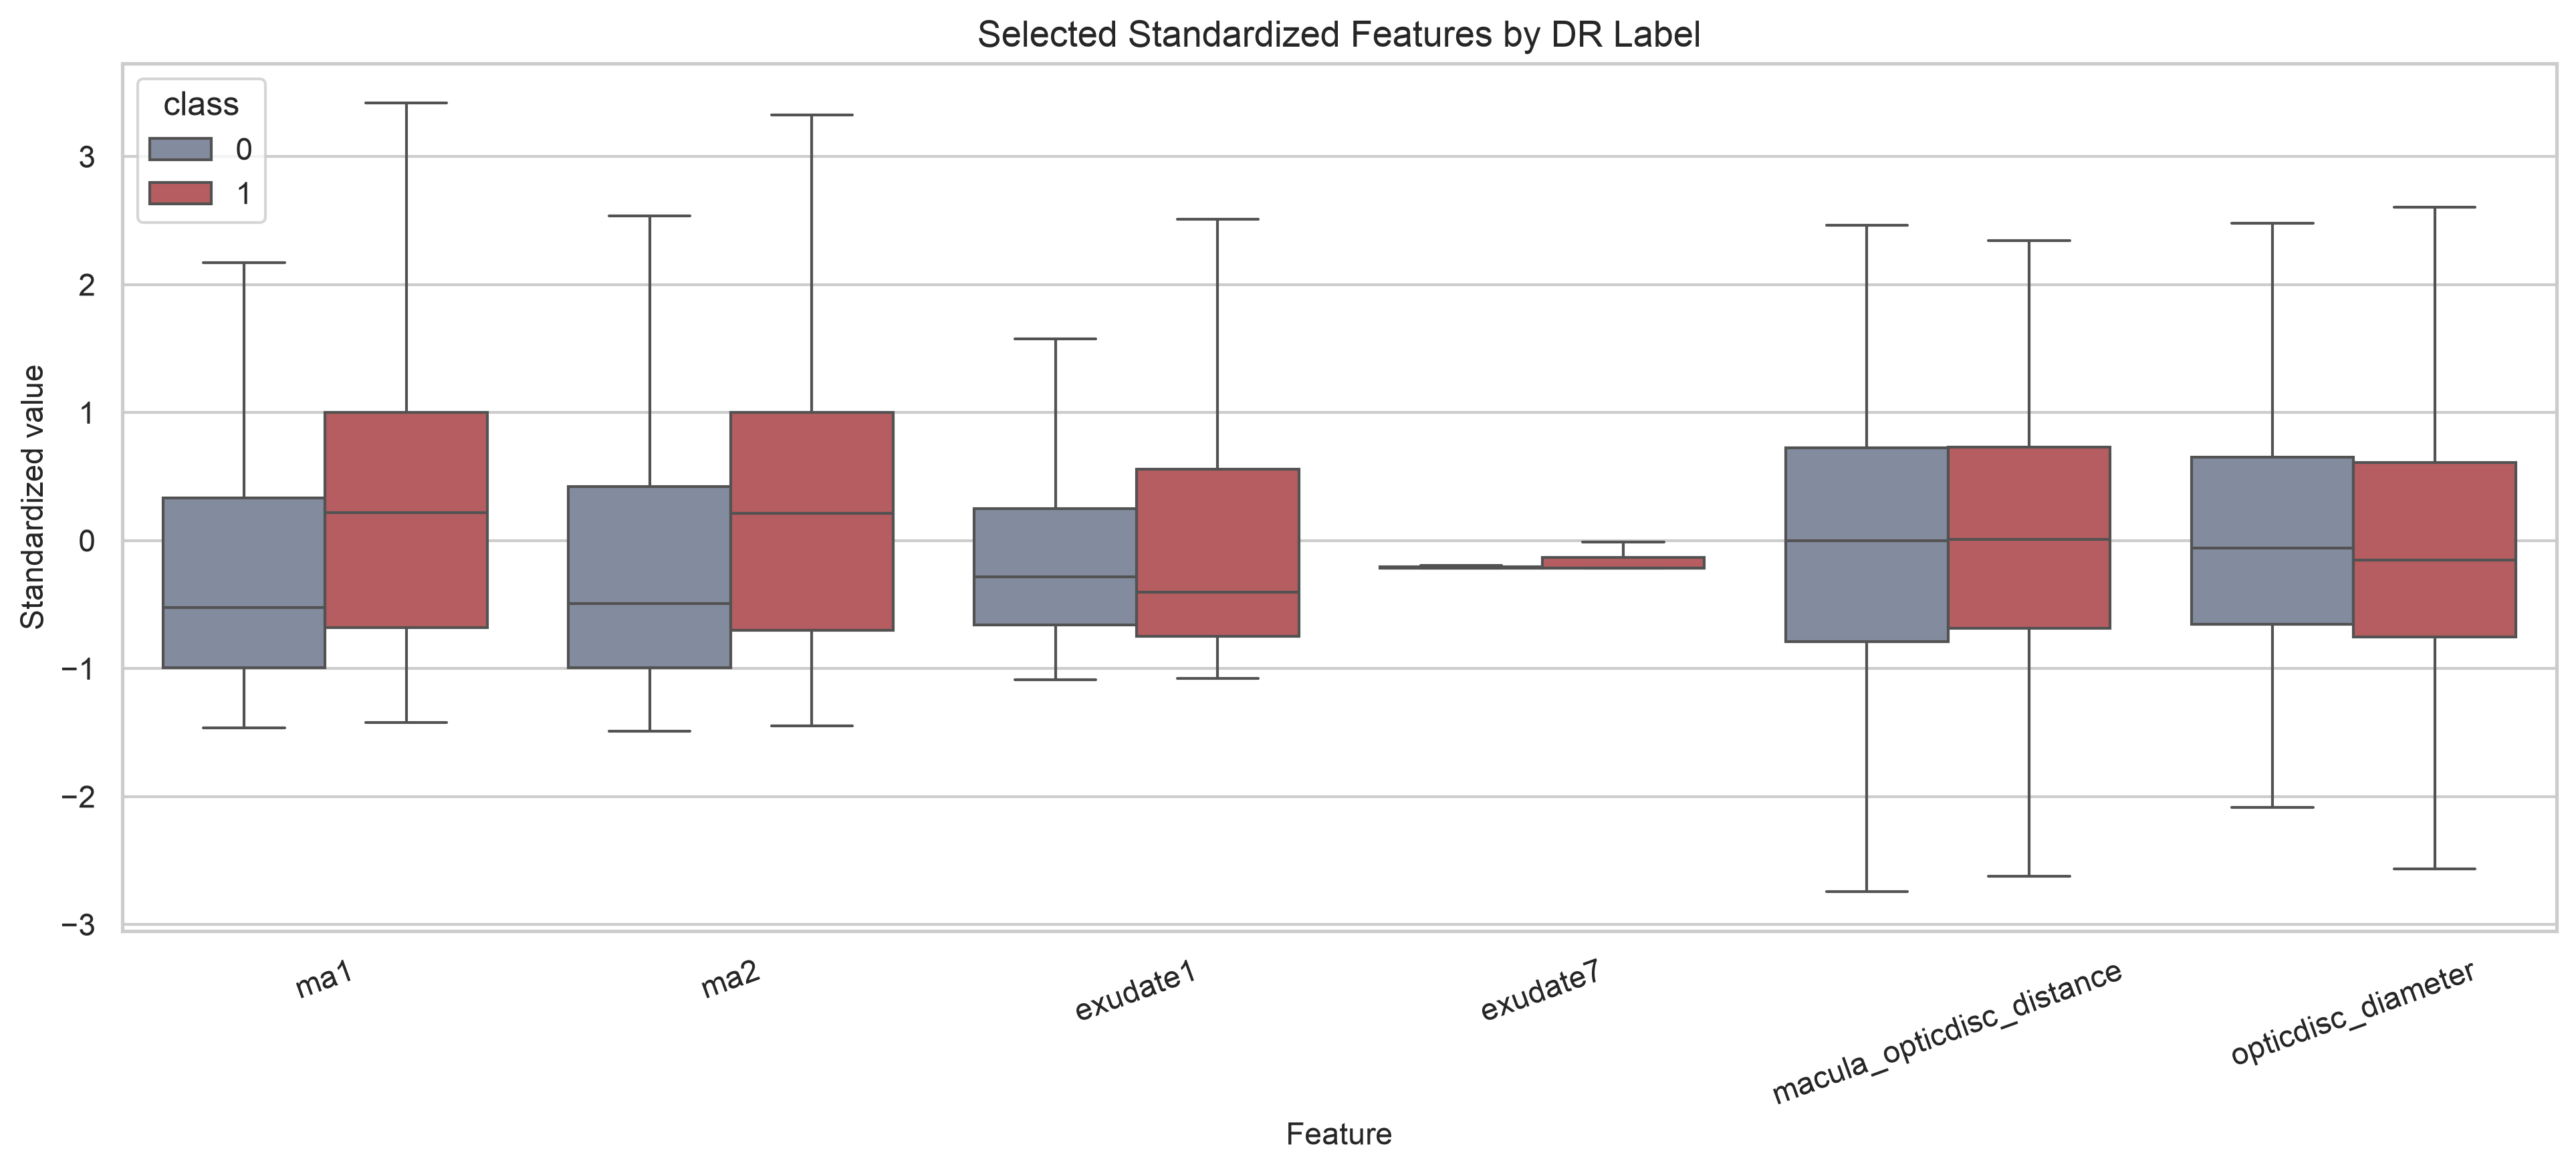

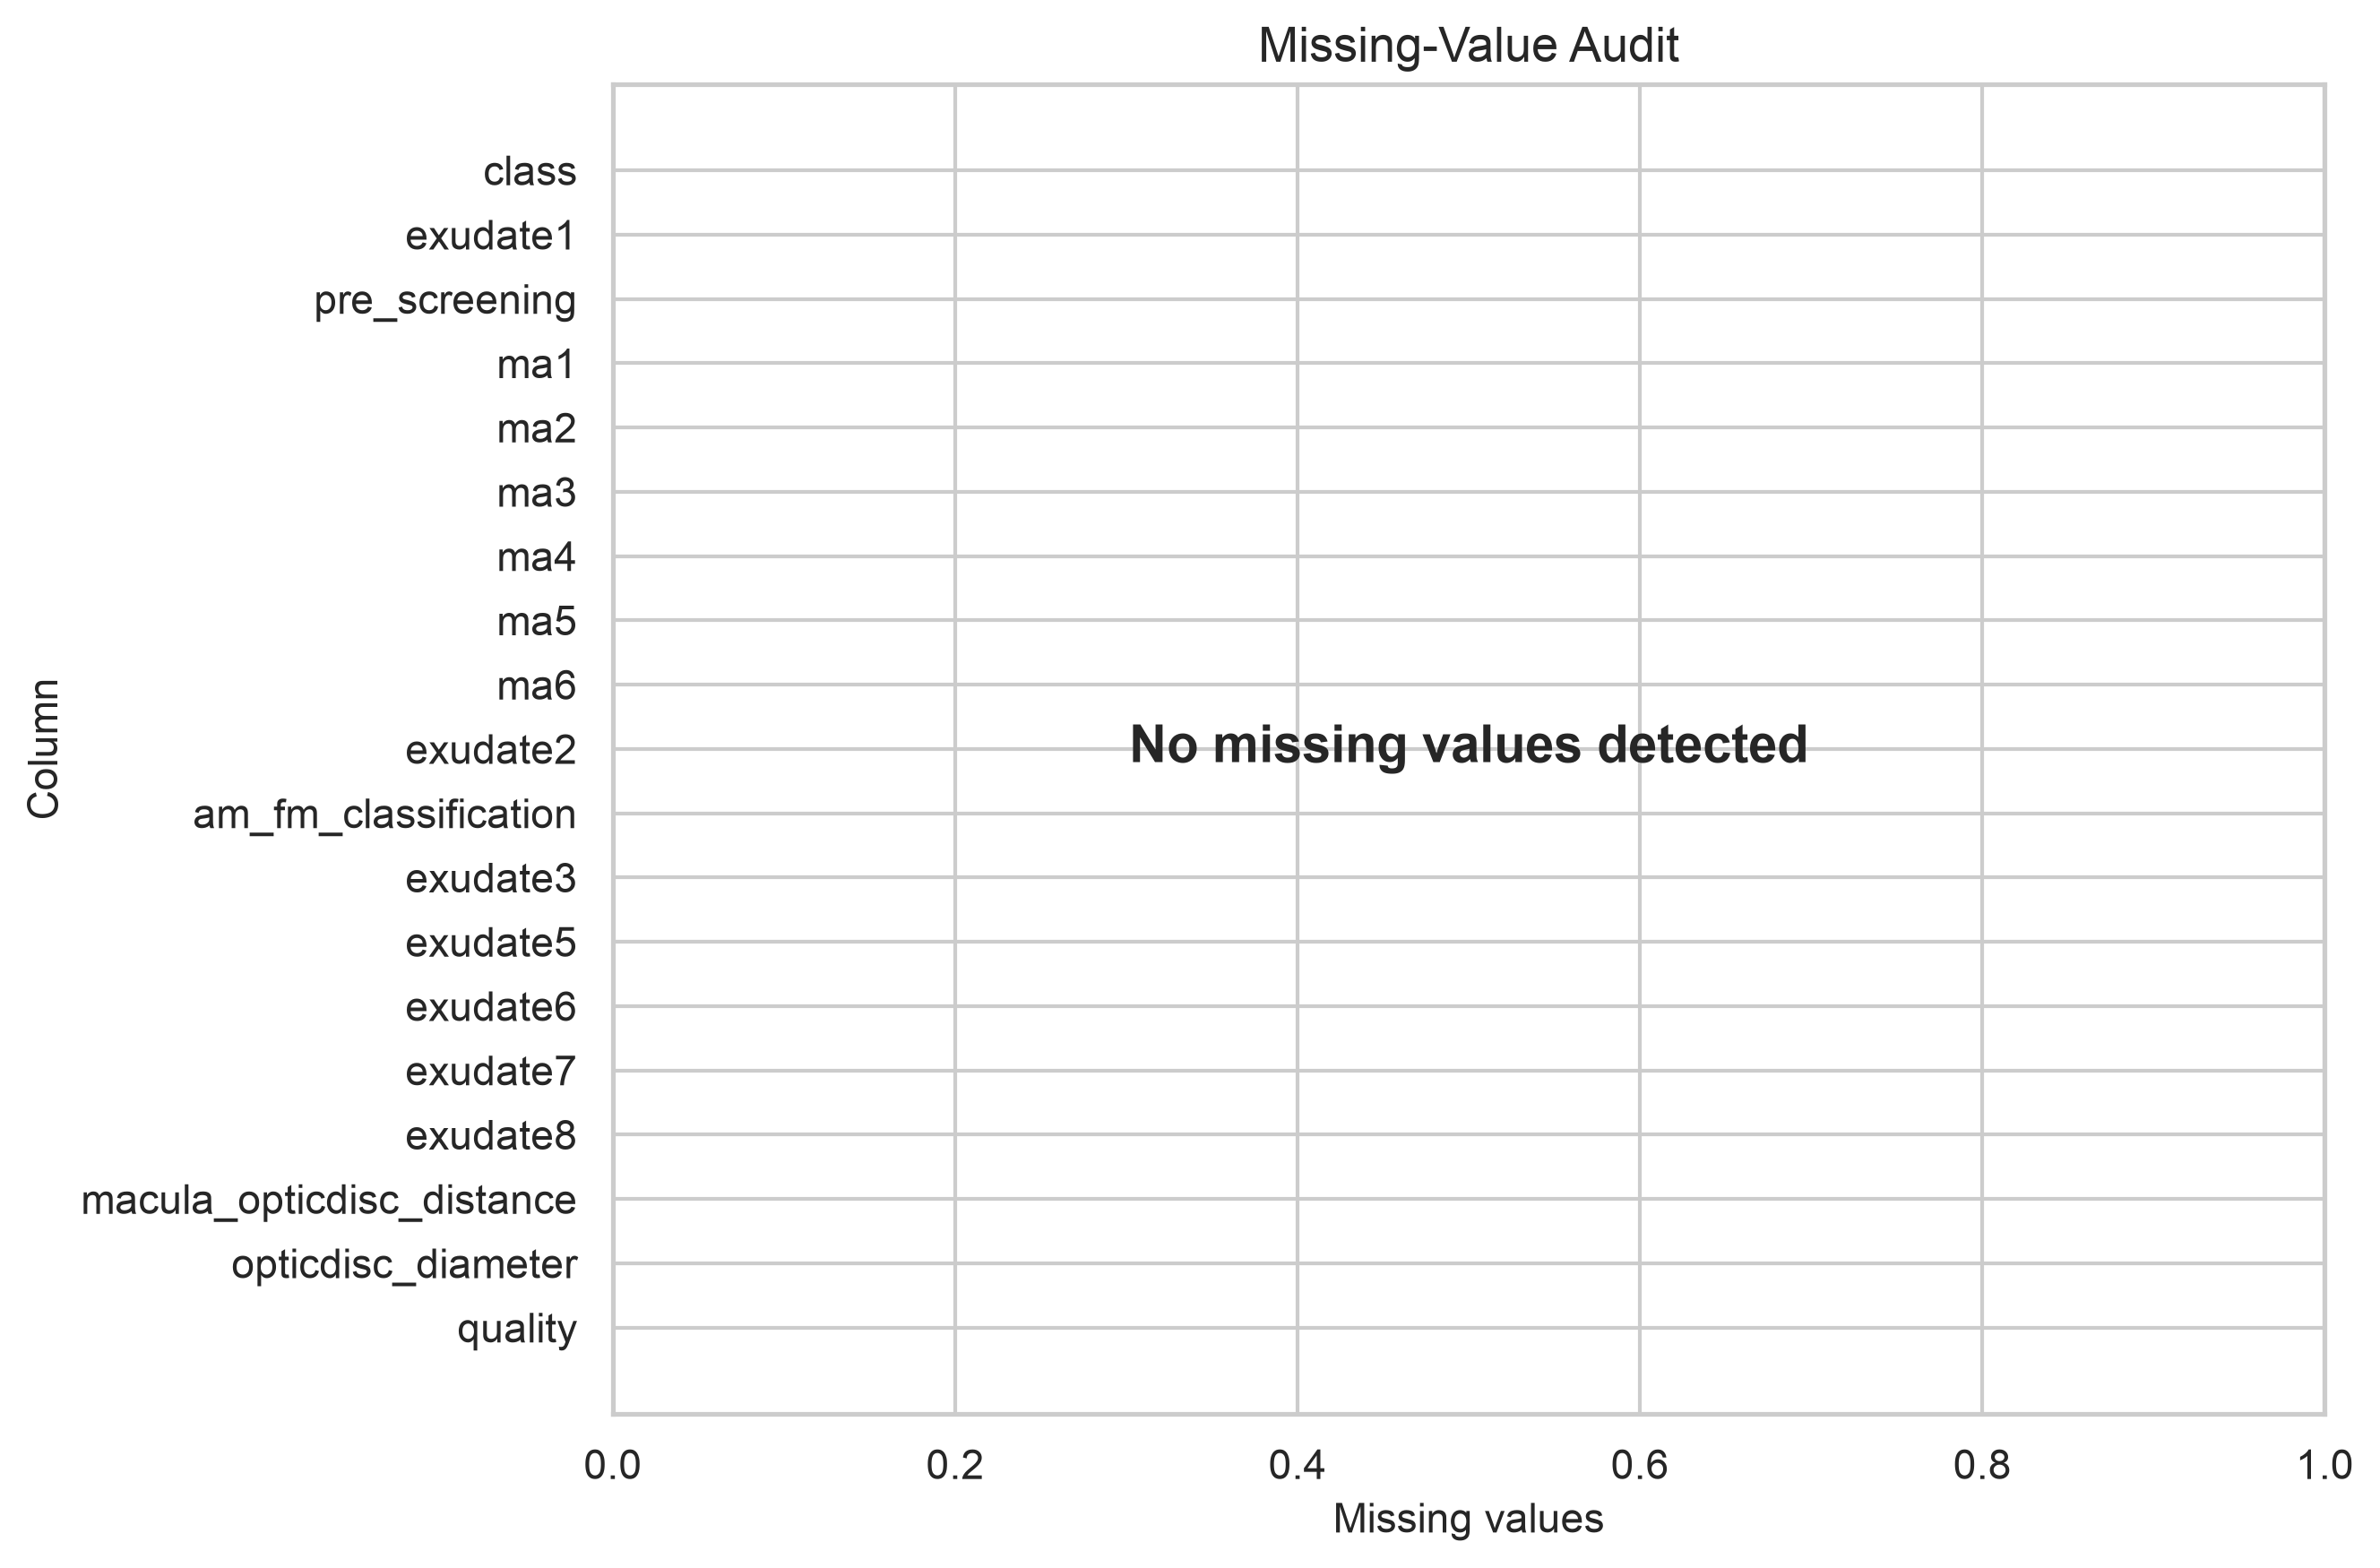

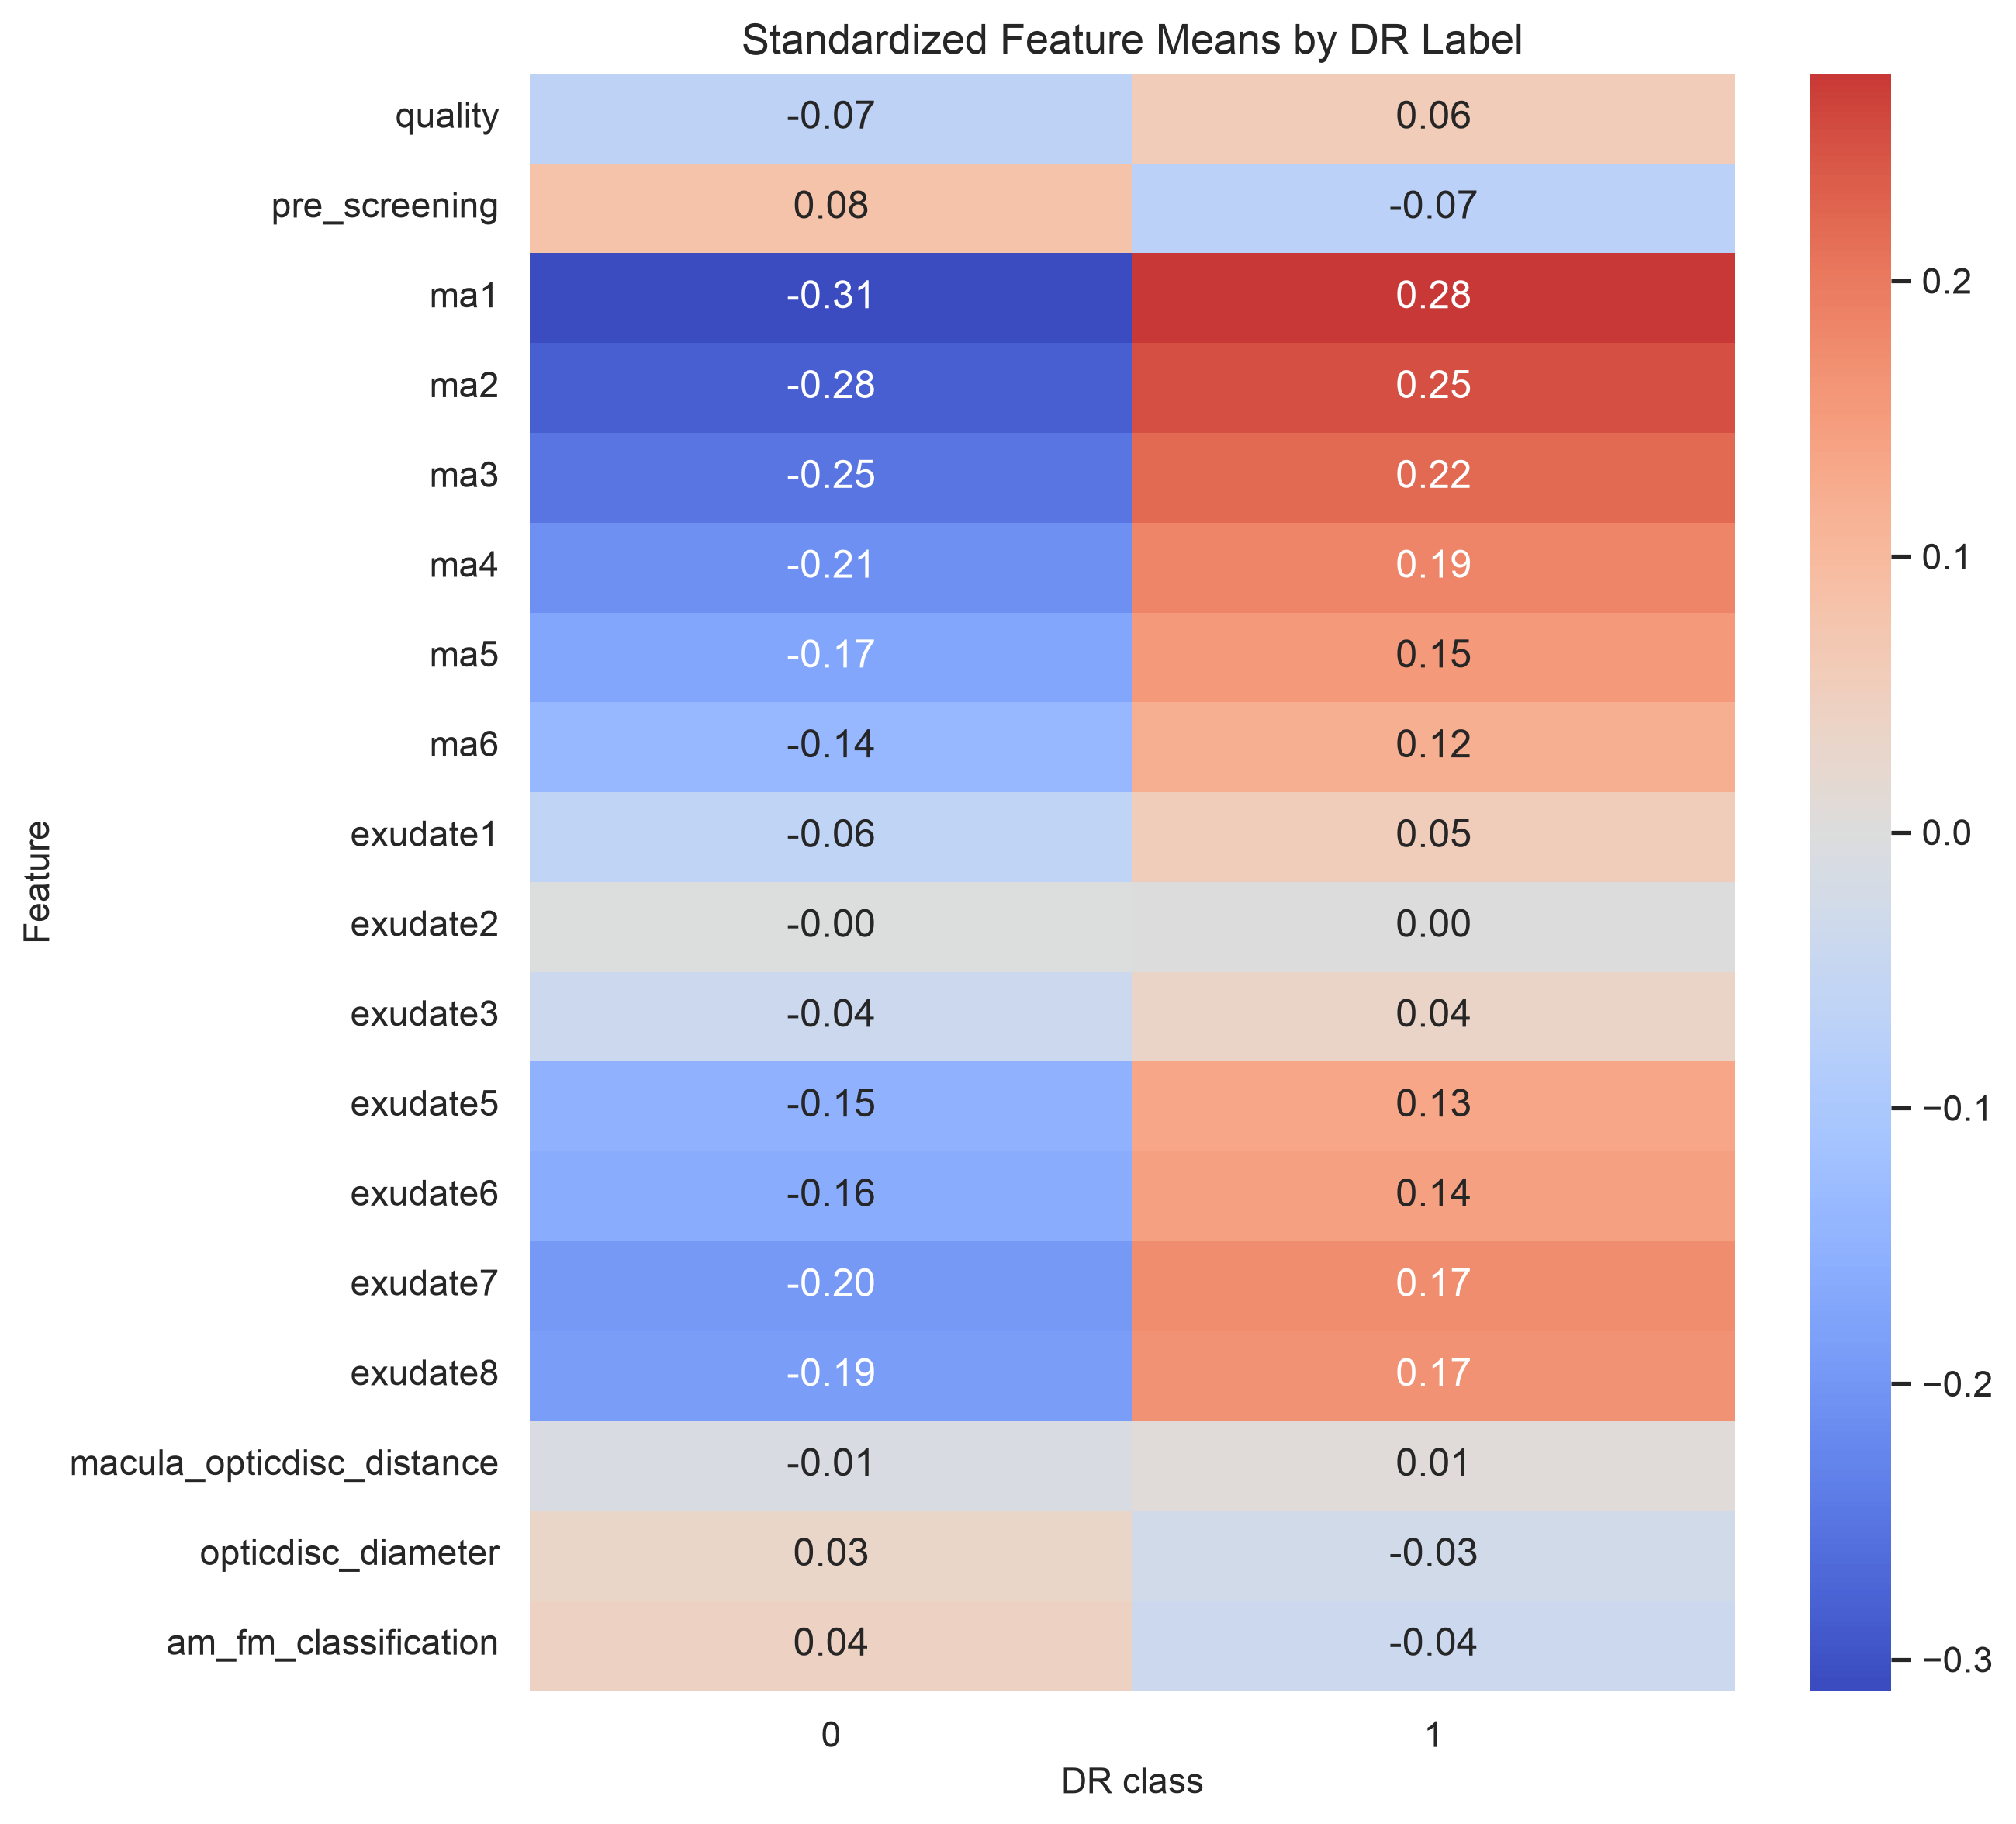

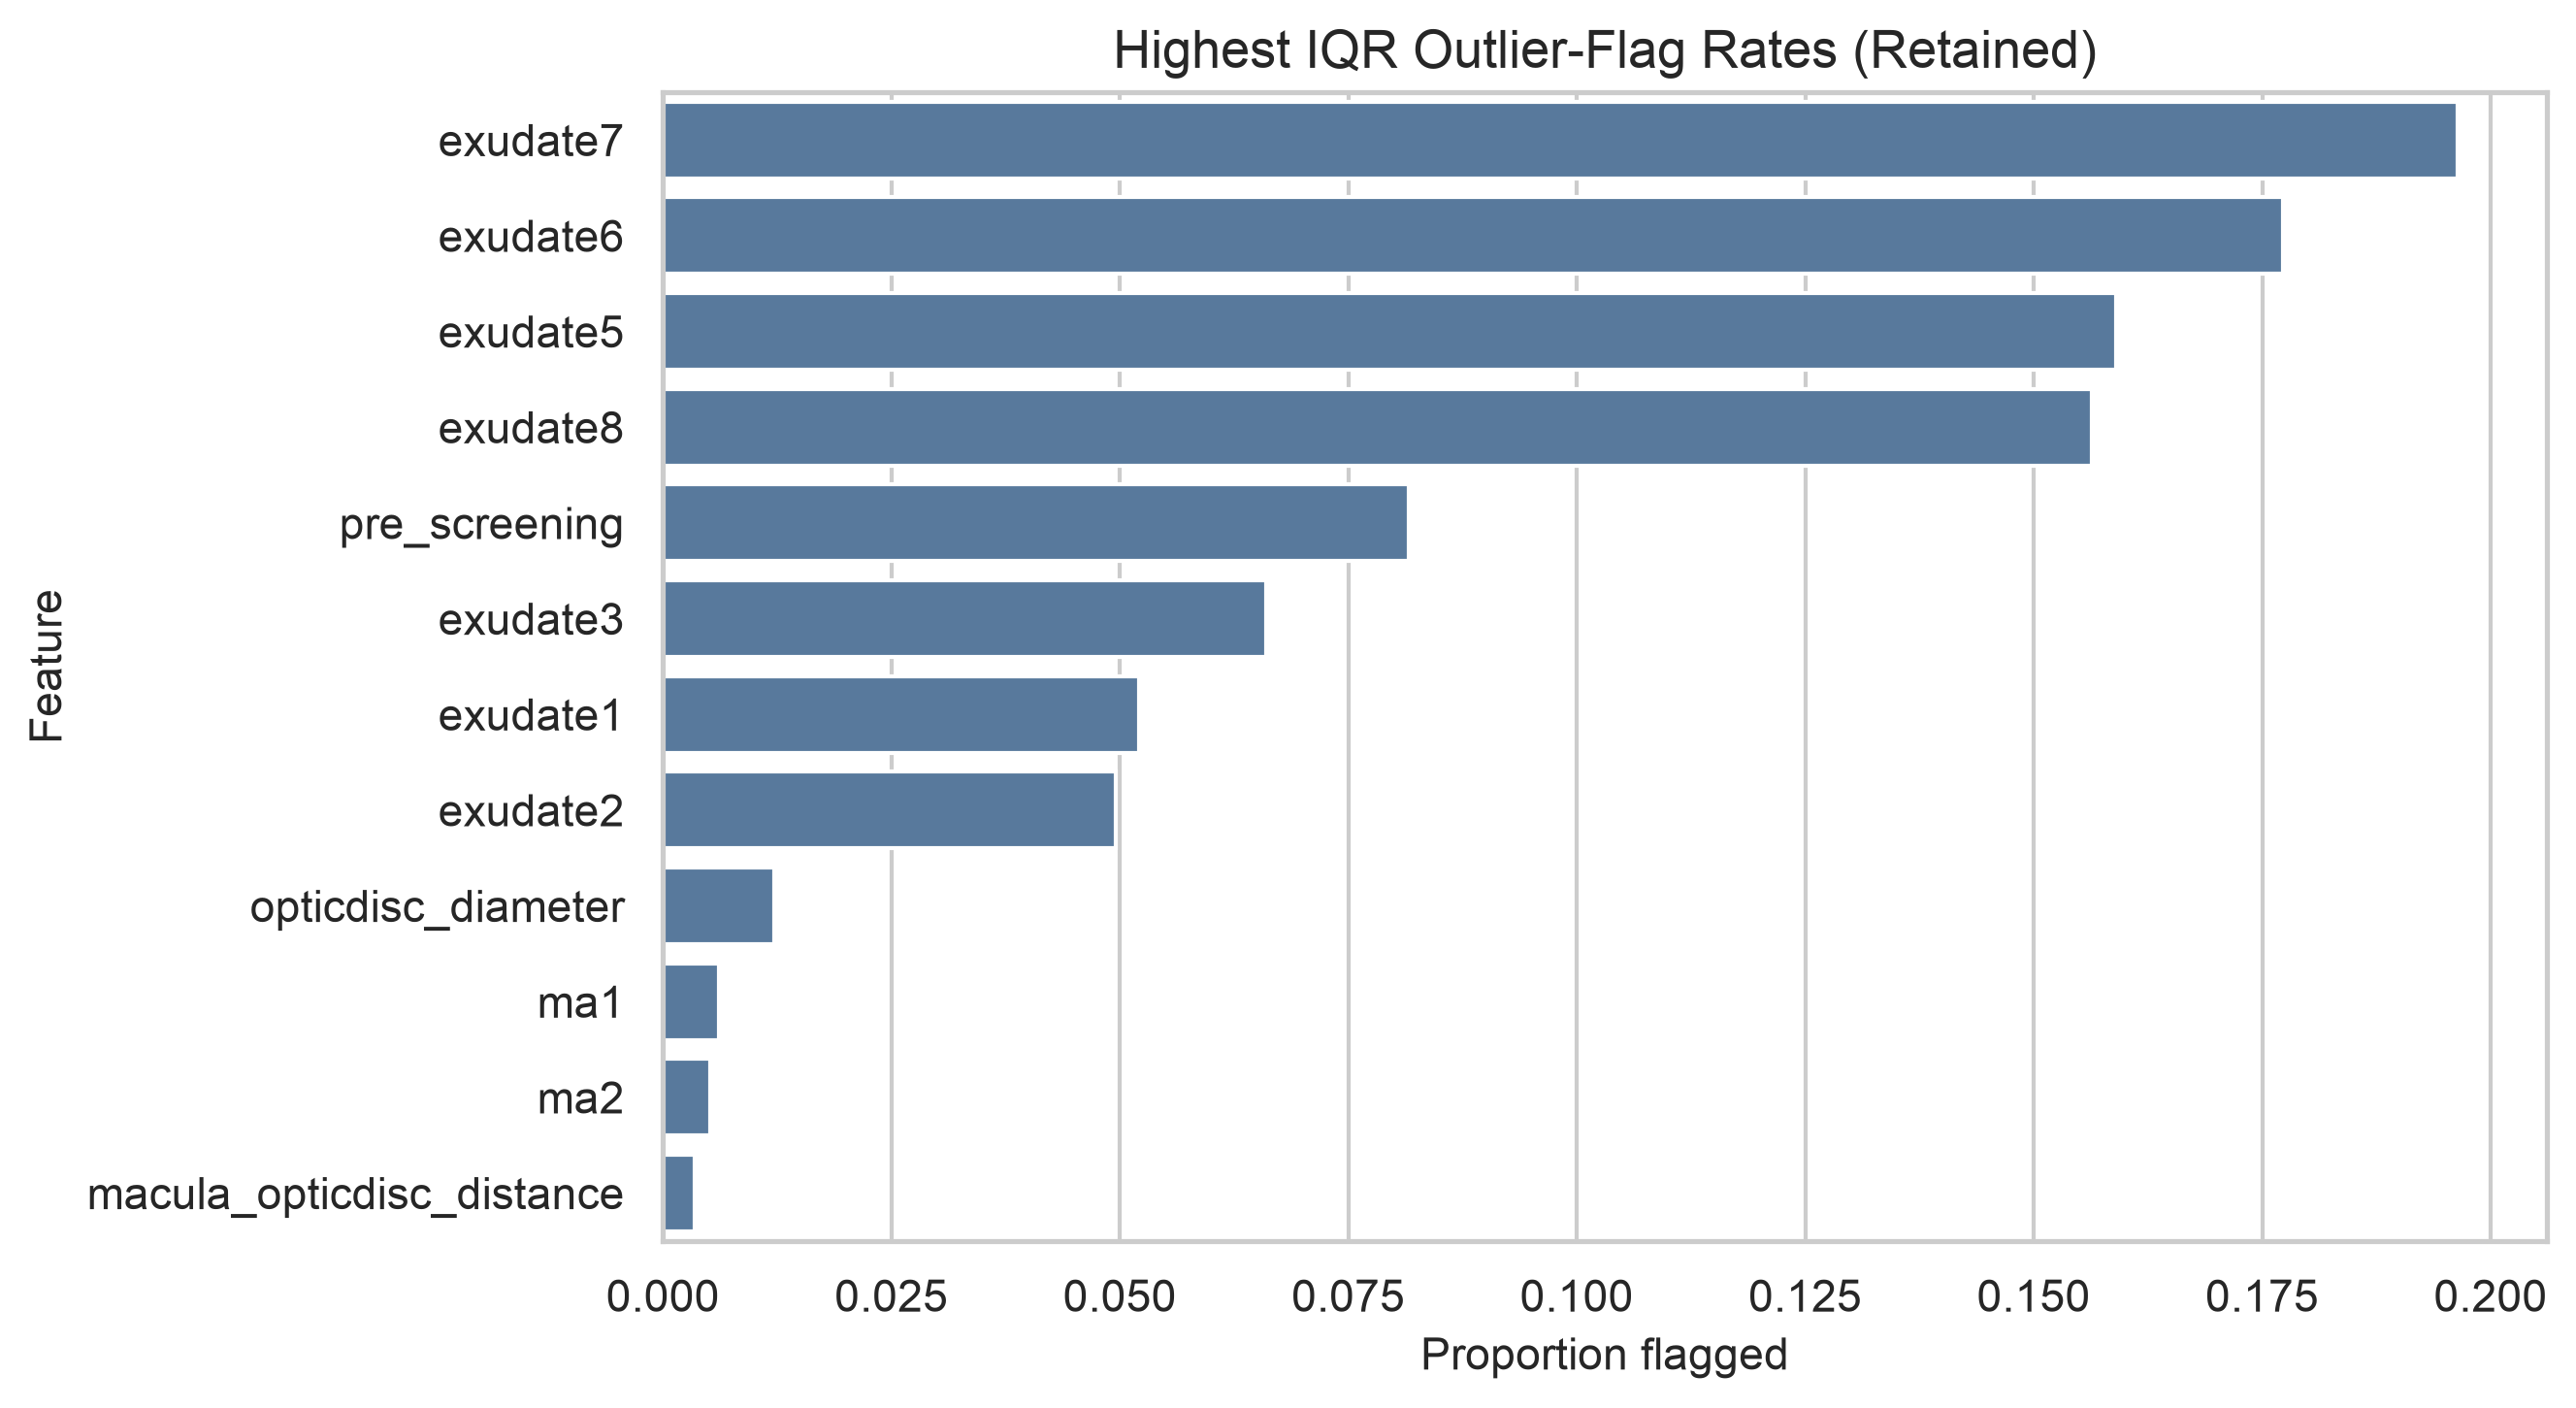

In [5]:
for name in [
    '01_class_distribution.png', '02_selected_feature_histograms.png',
    '03_feature_correlation_heatmap.png', '04_feature_boxplots_by_target.png',
    '05_missing_values.png', '06_feature_target_comparison.png',
    '07_outlier_flag_rates.png']:
    display(Image(filename=str(EDA / name)))

### EDA interpretation

The positive class is modestly larger. Microaneurysm detector outputs show strong mutual relationships and higher standardized means for class 1. IQR extremes are retained because detector extremes may contain information. No imputation is required.

In [6]:
print('Class distribution:')
display(frame['class'].value_counts().sort_index().rename('count').to_frame())
corr = frame[FEATURES].corr().abs()
pairs = corr.where(~corr.eq(1.0)).stack().sort_values(ascending=False)
display(pairs.head(10).rename('absolute_correlation').to_frame())

Class distribution:


,count
class,
0,540
1,611


absolute_correlation
ma2 ma1              0.996177
ma1 ma2              0.996177
ma3 ma2              0.994221
ma2 ma3              0.994221
ma3 ma4              0.991821
ma4 ma3              0.991821
    ma5              0.988294
ma5 ma4              0.988294
ma1 ma3              0.985730
ma3 ma1              0.985730

## 5. Data Preprocessing and Leakage Prevention

Tree ensembles do not need standardization. A duplicate-aware StratifiedGroupKFold creates the approximate 80/20 holdout, keeping identical vectors in one partition. All tuning uses training data only.

In [7]:
split_summary = pd.read_csv(RESULTS / 'data_split_summary.csv')
display(split_summary)
train_idx = set(pd.read_csv(RESULTS / 'training_indices.csv').row_index)
test_idx = set(pd.read_csv(RESULTS / 'test_indices.csv').row_index)
print('Row-index overlap:', len(train_idx & test_idx))
print('Held-out test used only after model selection.')

,partition,observations,class_0,class_1
0,Training,920,432,488
1,Held-out test,231,108,123


Row-index overlap: 0
Held-out test used only after model selection.


## 6. Model 1 — Bagged Decision Trees

Bagging trains decision trees independently on bootstrap samples and averages their predictions. Every base tree may consider all predictors at a split, distinguishing it from Random Forest.

In [8]:
best = json.loads((RESULTS / 'best_hyperparameters.json').read_text())
display(pd.Series(best['Bagging']['parameters'], name='selected_value').to_frame())
print('Best training-only CV F1:', round(best['Bagging']['training_cv_best_f1'], 4))

,selected_value
estimator__max_depth,NaN
estimator__min_samples_leaf,3.0
max_samples,0.8
n_estimators,300.0


Best training-only CV F1: 0.6849


## 7. Model 2 — Standard Gradient Boosting

Gradient Boosting builds shallow trees sequentially to reduce current ensemble errors. This is scikit-learn GradientBoostingClassifier, not AdaBoost, XGBoost, LightGBM, or HistGradientBoosting.

In [9]:
display(pd.Series(best['Gradient Boosting']['parameters'], name='selected_value').to_frame())
print('Best training-only CV F1:', round(best['Gradient Boosting']['training_cv_best_f1'], 4))

,selected_value
learning_rate,0.1
max_depth,2.0
n_estimators,200.0
subsample,0.8


Best training-only CV F1: 0.7181


## 8. Model 3 — Random Forest

Random Forest is specialized Bagging: it combines bootstrap sampling with random feature selection at splits. Random feature selection is the critical difference from ordinary Bagging here.

In [10]:
display(pd.Series(best['Random Forest']['parameters'], name='selected_value').to_frame())
print('Best training-only CV F1:', round(best['Random Forest']['training_cv_best_f1'], 4))

,selected_value
max_depth,16
max_features,sqrt
min_samples_leaf,1
n_estimators,100


Best training-only CV F1: 0.7031


## 9. Hyperparameter Tuning

Each method receives 24 candidate configurations and the same five grouped training folds. F1 is the refit criterion because it balances positive-class precision and sensitivity. The test set is excluded from selection.

In [11]:
for model in ['bagging', 'gradient_boosting', 'random_forest']:
    search = pd.read_csv(RESULTS / f'{model}_hyperparameter_search.csv')
    print(model.replace('_', ' ').title(), '— candidates:', len(search))
    display(search.head(3))

Bagging — candidates: 24


,params,mean_train_score,std_train_score,mean_test_score,std_test_score,rank_test_score,mean_fit_time,mean_score_time
0,"{'estimator__max_depth': None, 'estimator__min...",0.979887,0.004438,0.684874,0.026089,1,0.660369,0.048318
1,"{'estimator__max_depth': None, 'estimator__min...",0.975685,0.001810,0.683477,0.027489,2,0.168258,0.026561
2,"{'estimator__max_depth': 12, 'estimator__min_s...",0.970981,0.005842,0.682451,0.018643,3,0.612041,0.048244


Gradient Boosting — candidates: 24


,params,mean_train_score,std_train_score,mean_test_score,std_test_score,rank_test_score,mean_fit_time,mean_score_time
0,"{'learning_rate': 0.1, 'max_depth': 2, 'n_esti...",0.901516,0.005198,0.718095,0.022334,1,0.199446,0.002196
1,"{'learning_rate': 0.1, 'max_depth': 3, 'n_esti...",0.991265,0.002481,0.713517,0.015282,2,0.266703,0.002664
2,"{'learning_rate': 0.1, 'max_depth': 3, 'n_esti...",0.922836,0.002221,0.708058,0.035899,3,0.150872,0.002251


Random Forest — candidates: 24


,params,mean_train_score,std_train_score,mean_test_score,std_test_score,rank_test_score,mean_fit_time,mean_score_time
0,"{'max_depth': 16, 'max_features': 'sqrt', 'min...",1.000000,0.000000,0.703054,0.027930,1,0.121693,0.025238
1,"{'max_depth': 16, 'max_features': 'sqrt', 'min...",1.000000,0.000000,0.701665,0.020956,2,0.375129,0.039924
2,"{'max_depth': None, 'max_features': 'sqrt', 'm...",0.975548,0.002951,0.696454,0.024921,3,0.111754,0.018868


## 10. Cross-validation Stability

Fold-level performance describes internal training stability. It does not establish clinical robustness or external generalization.

accuracy            f1_score             roc_auc          
                       mean       std      mean       std      mean       std
model                                                                        
Bagging            0.676087  0.019820  0.684874  0.029168  0.747496  0.026939
Gradient Boosting  0.703261  0.016574  0.718095  0.024970  0.771212  0.016254
Random Forest      0.692391  0.025665  0.703054  0.031227  0.760892  0.030253

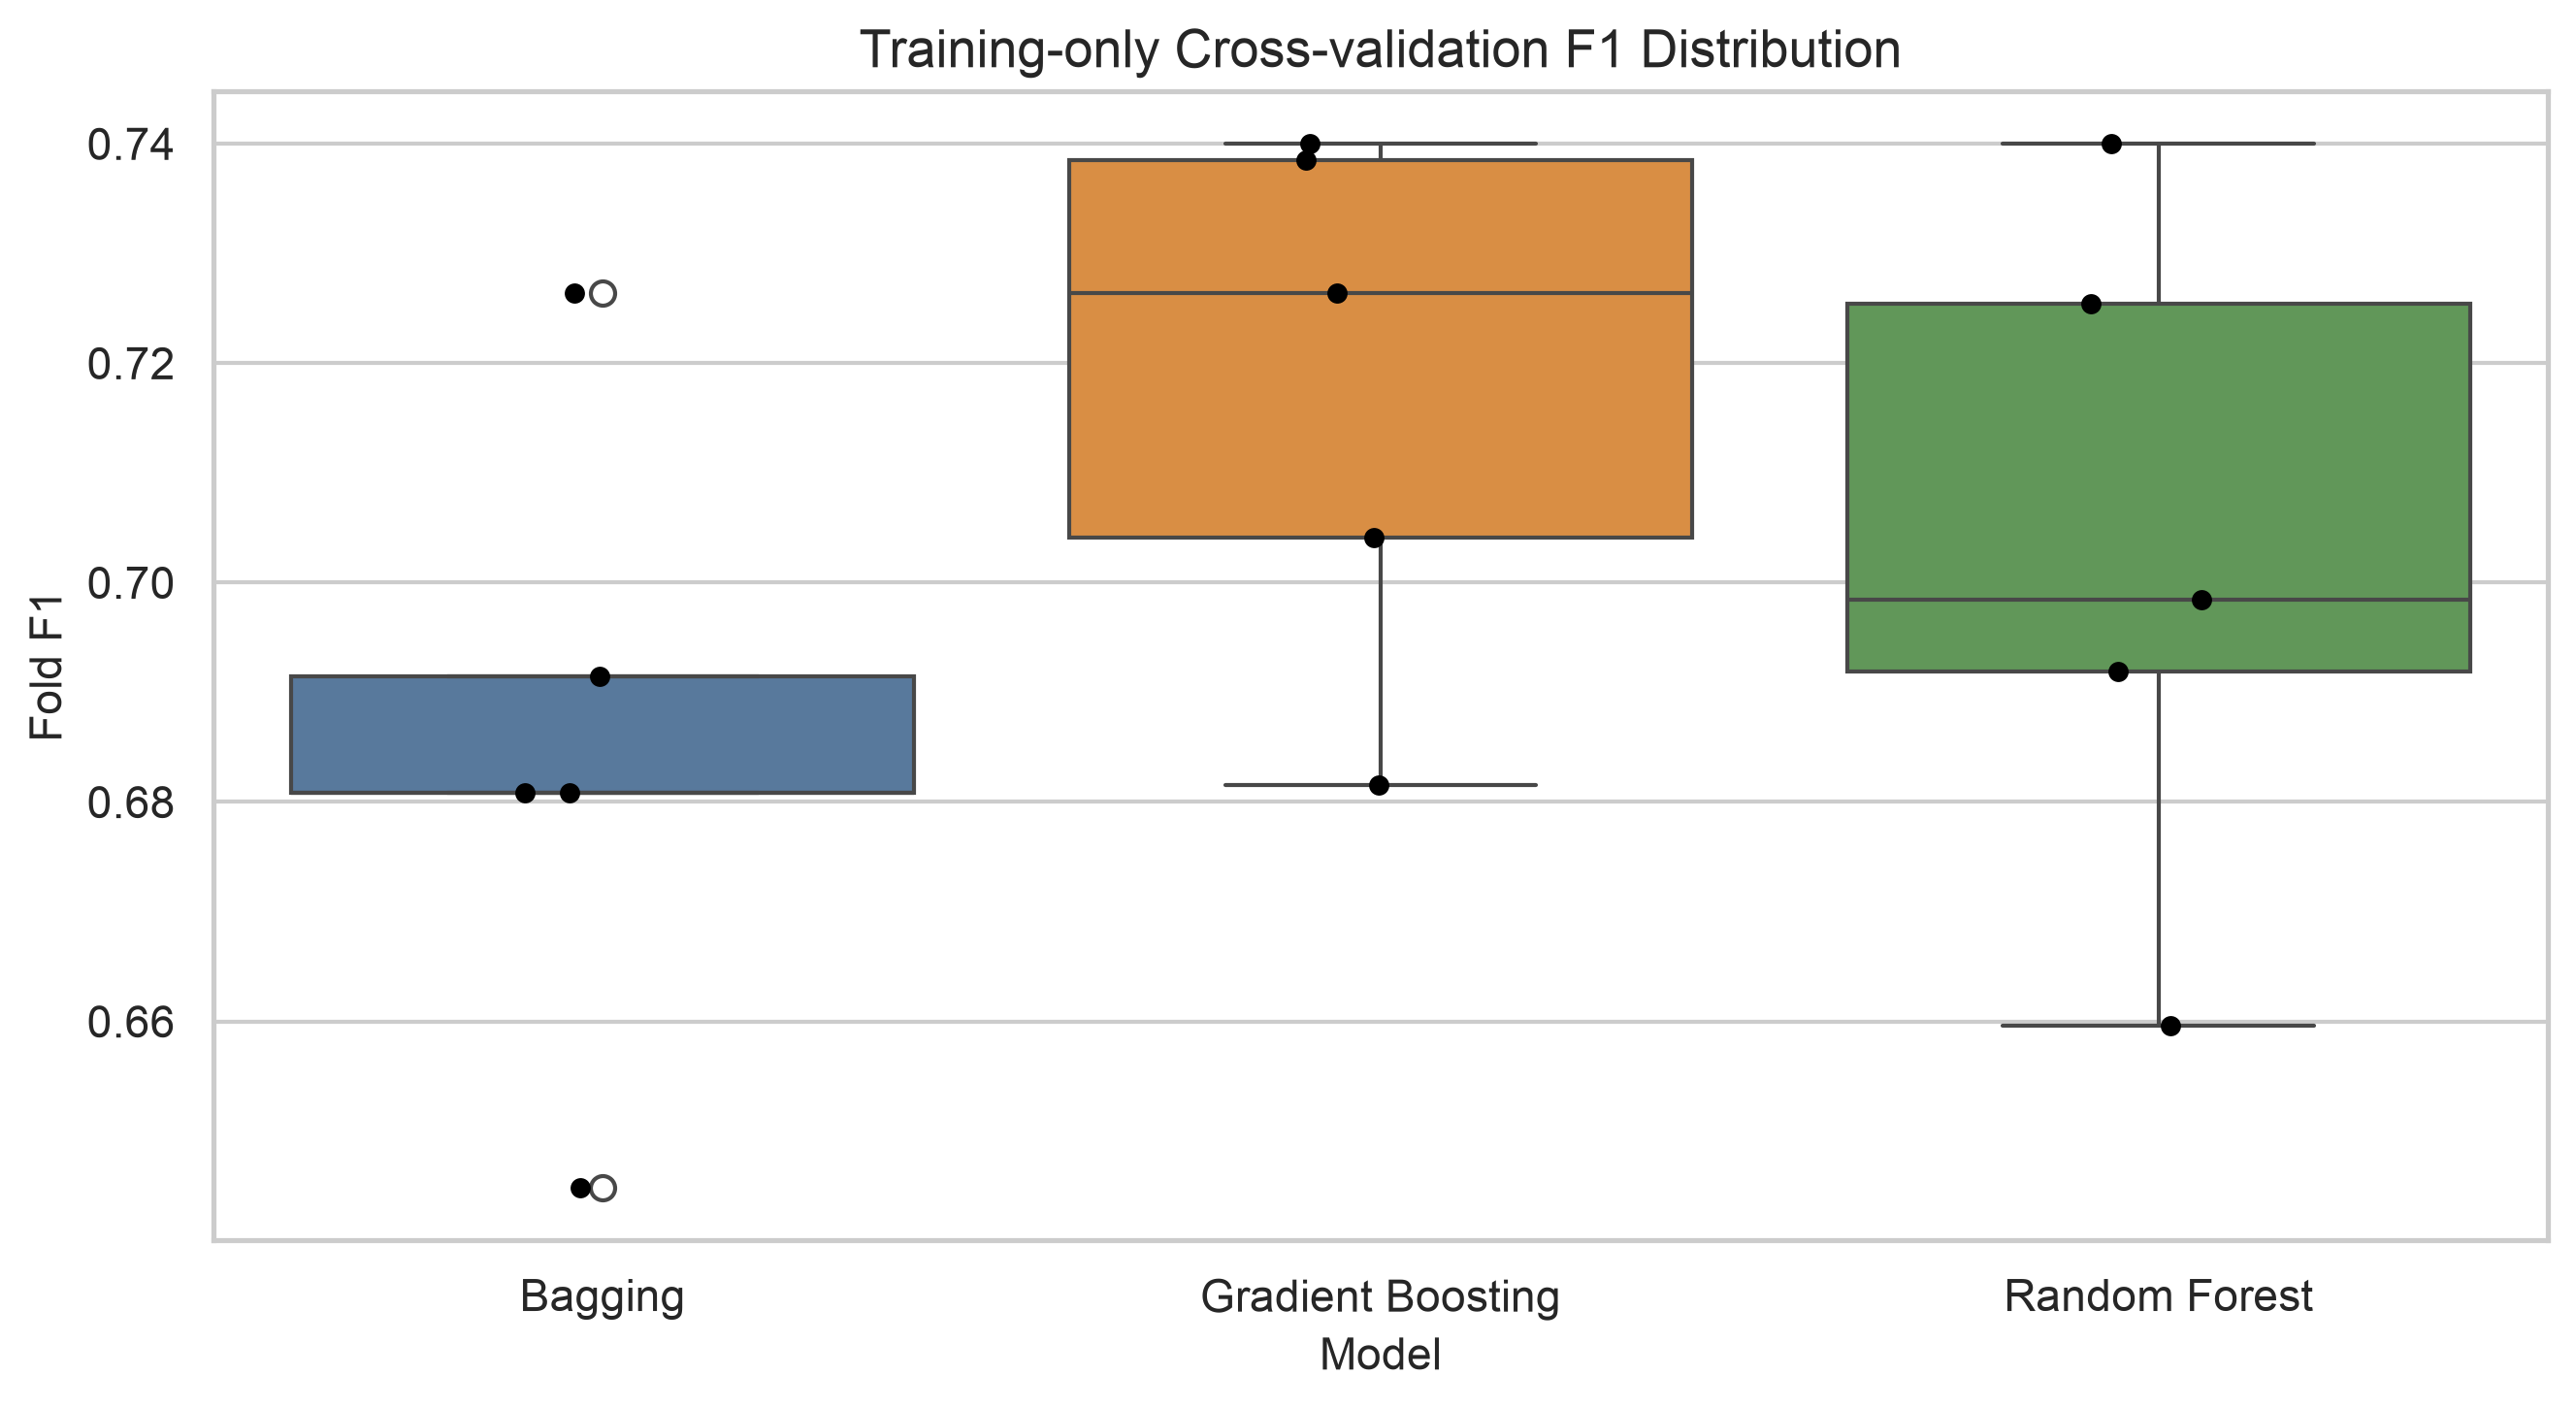

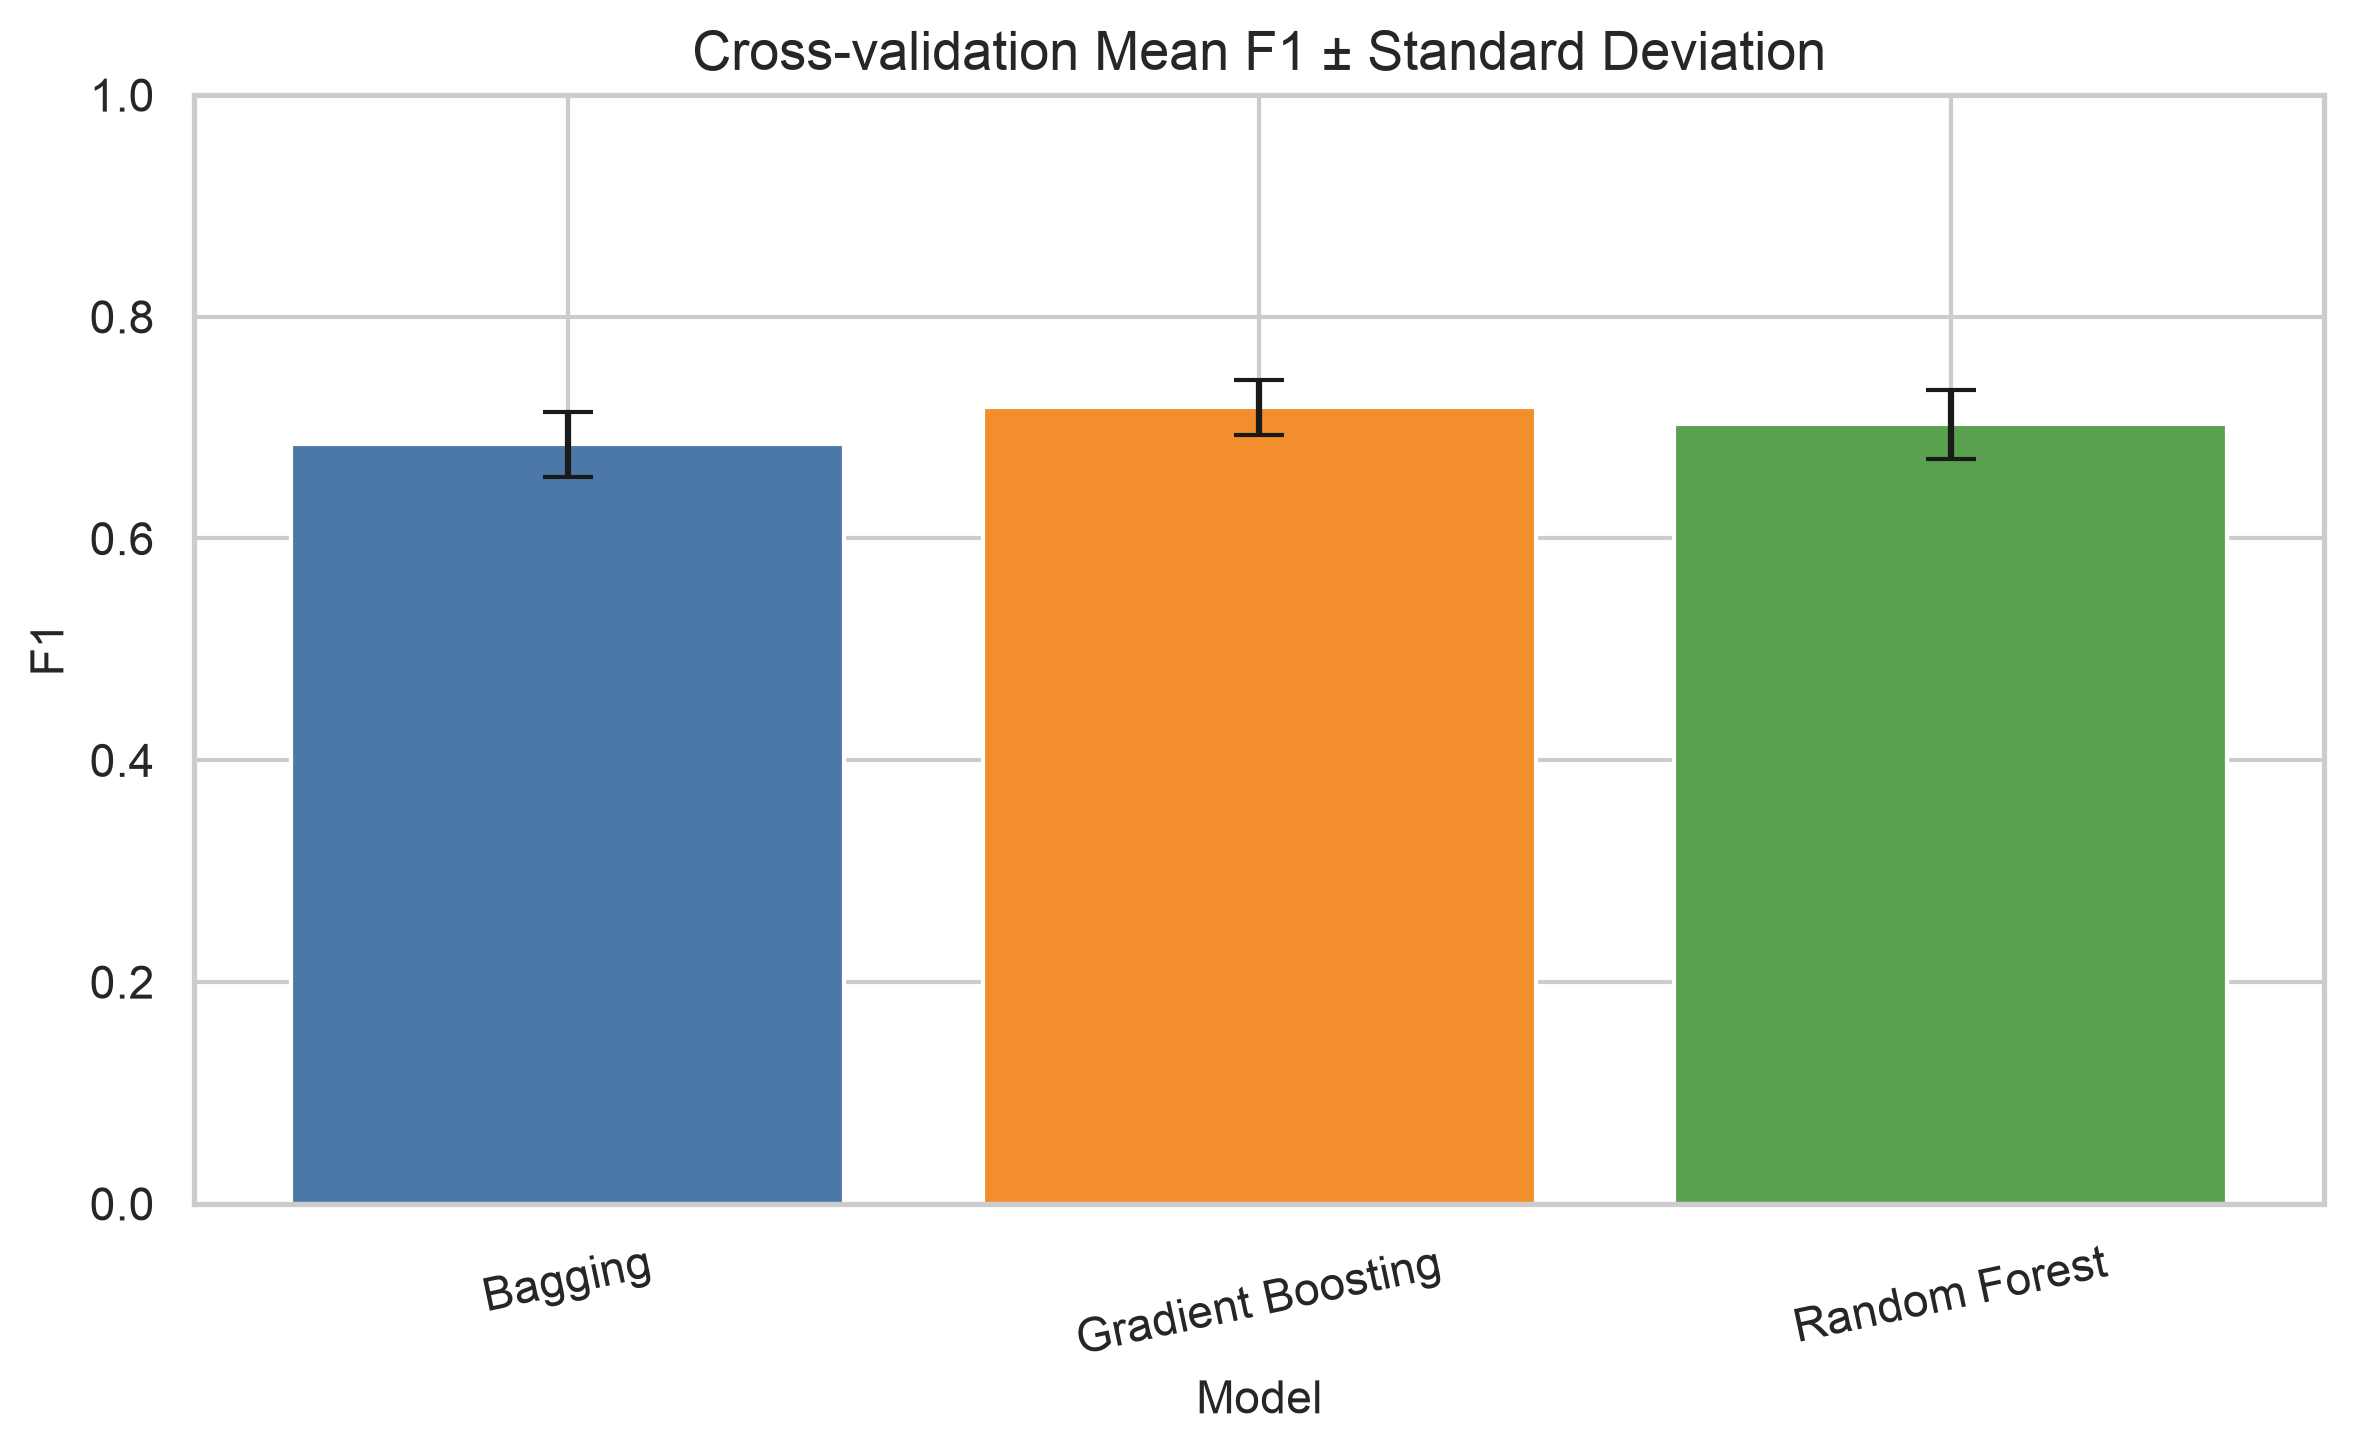

In [12]:
folds = pd.read_csv(RESULTS / 'cross_validation_results.csv')
display(folds.groupby('model')[['accuracy','f1_score','roc_auc']].agg(['mean','std']))
display(Image(filename=str(MODELS / '04_cross_validation_distribution.png')))
display(Image(filename=str(MODELS / '08_cv_mean_stability.png')))

## 11. Held-out Test Evaluation

Class 1 is positive. Specificity is TN/(TN+FP). Gradient Boosting detects more positives here, while Bagging and Random Forest give slightly higher specificity.

,model,accuracy,precision,recall_sensitivity,specificity,f1_score,roc_auc,cv_mean_f1,cv_sd_f1
0,Bagging,0.7013,0.7288,0.6992,0.7037,0.7137,0.7771,0.6849,0.0292
1,Gradient Boosting,0.7273,0.7344,0.7642,0.6852,0.7490,0.8180,0.7181,0.0250
2,Random Forest,0.7056,0.7350,0.6992,0.7130,0.7167,0.7885,0.7031,0.0312


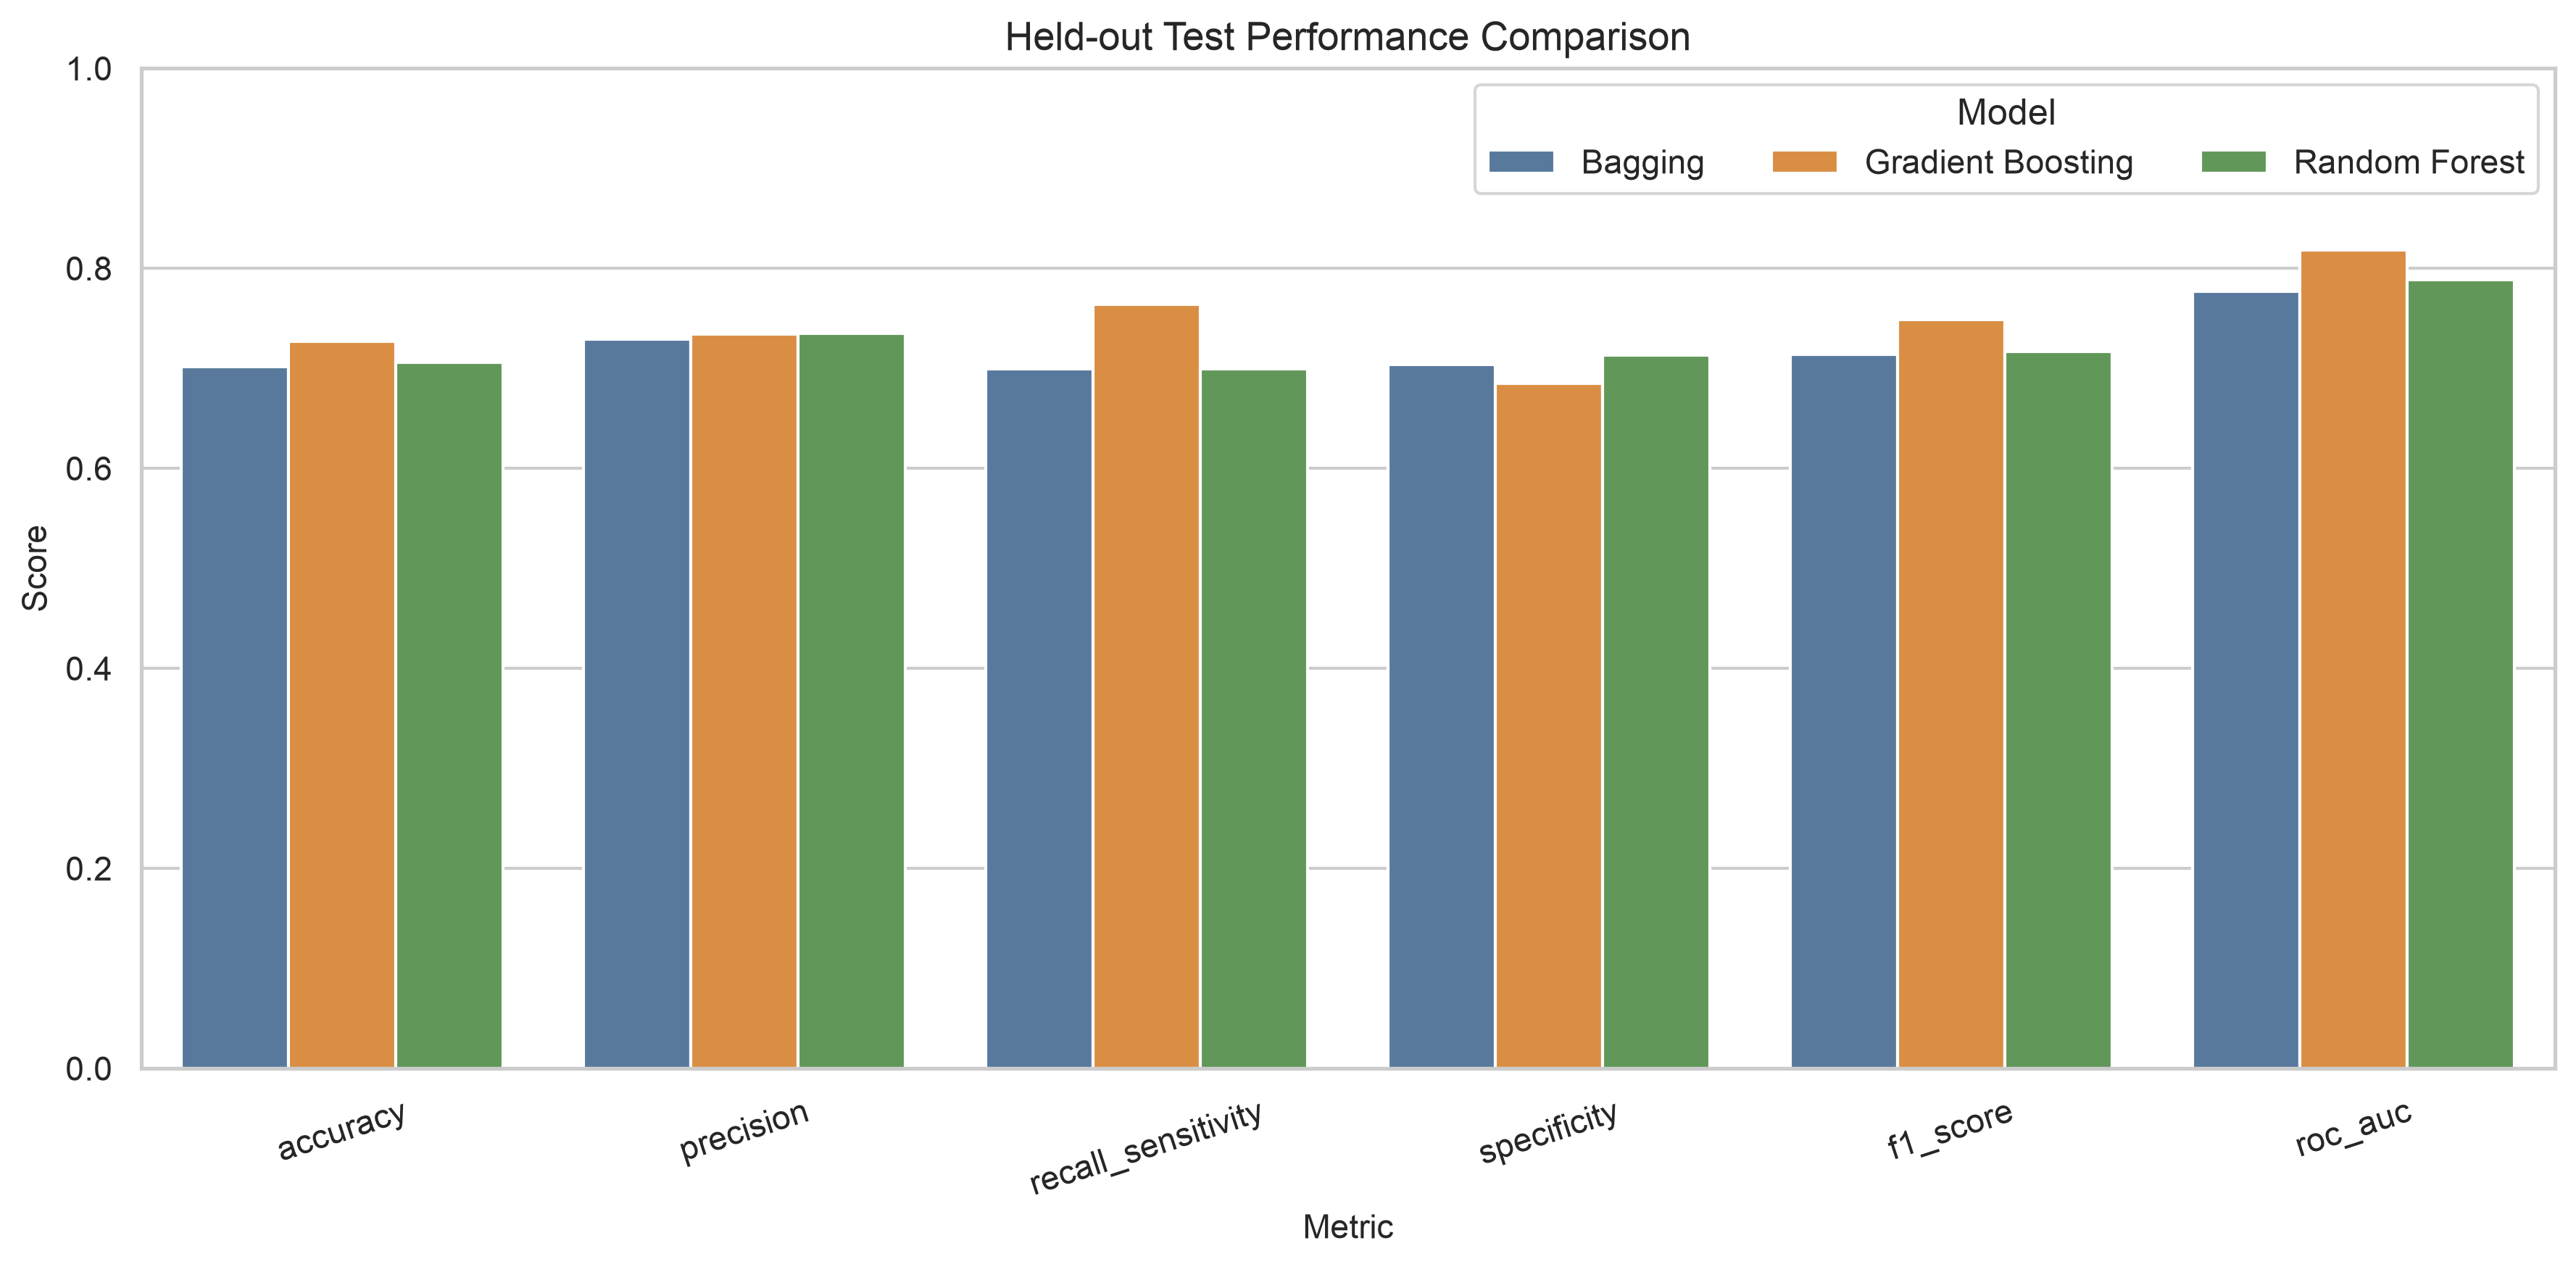

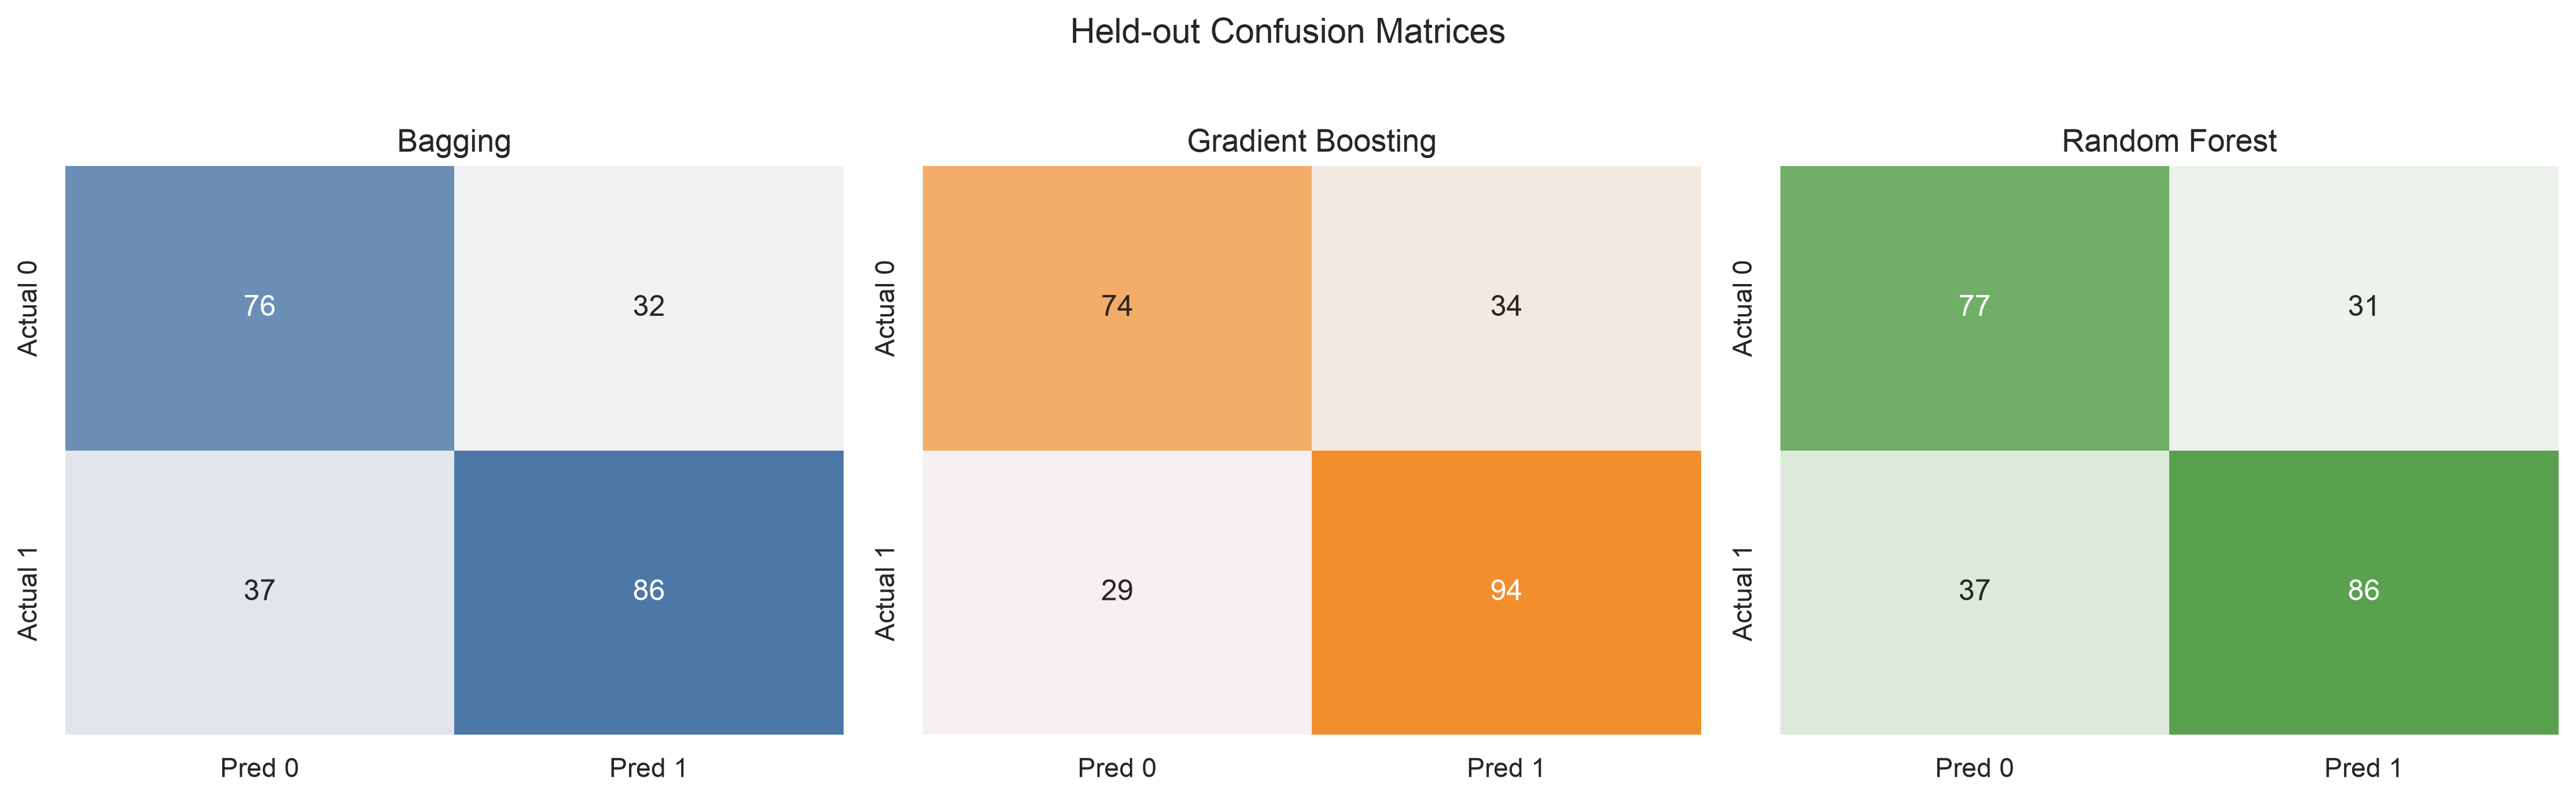

In [13]:
metrics = pd.read_csv(RESULTS / 'model_comparison.csv')
columns = ['model','accuracy','precision','recall_sensitivity','specificity','f1_score','roc_auc','cv_mean_f1','cv_sd_f1']
display(metrics[columns].round(4))
display(Image(filename=str(MODELS / '01_model_performance_comparison.png')))
display(Image(filename=str(MODELS / '02_confusion_matrices.png')))

## 12. Performance Visualizations

ROC curves summarize threshold-dependent discrimination. Timings are machine-specific. Feature importance is model-dependent association, not causality.

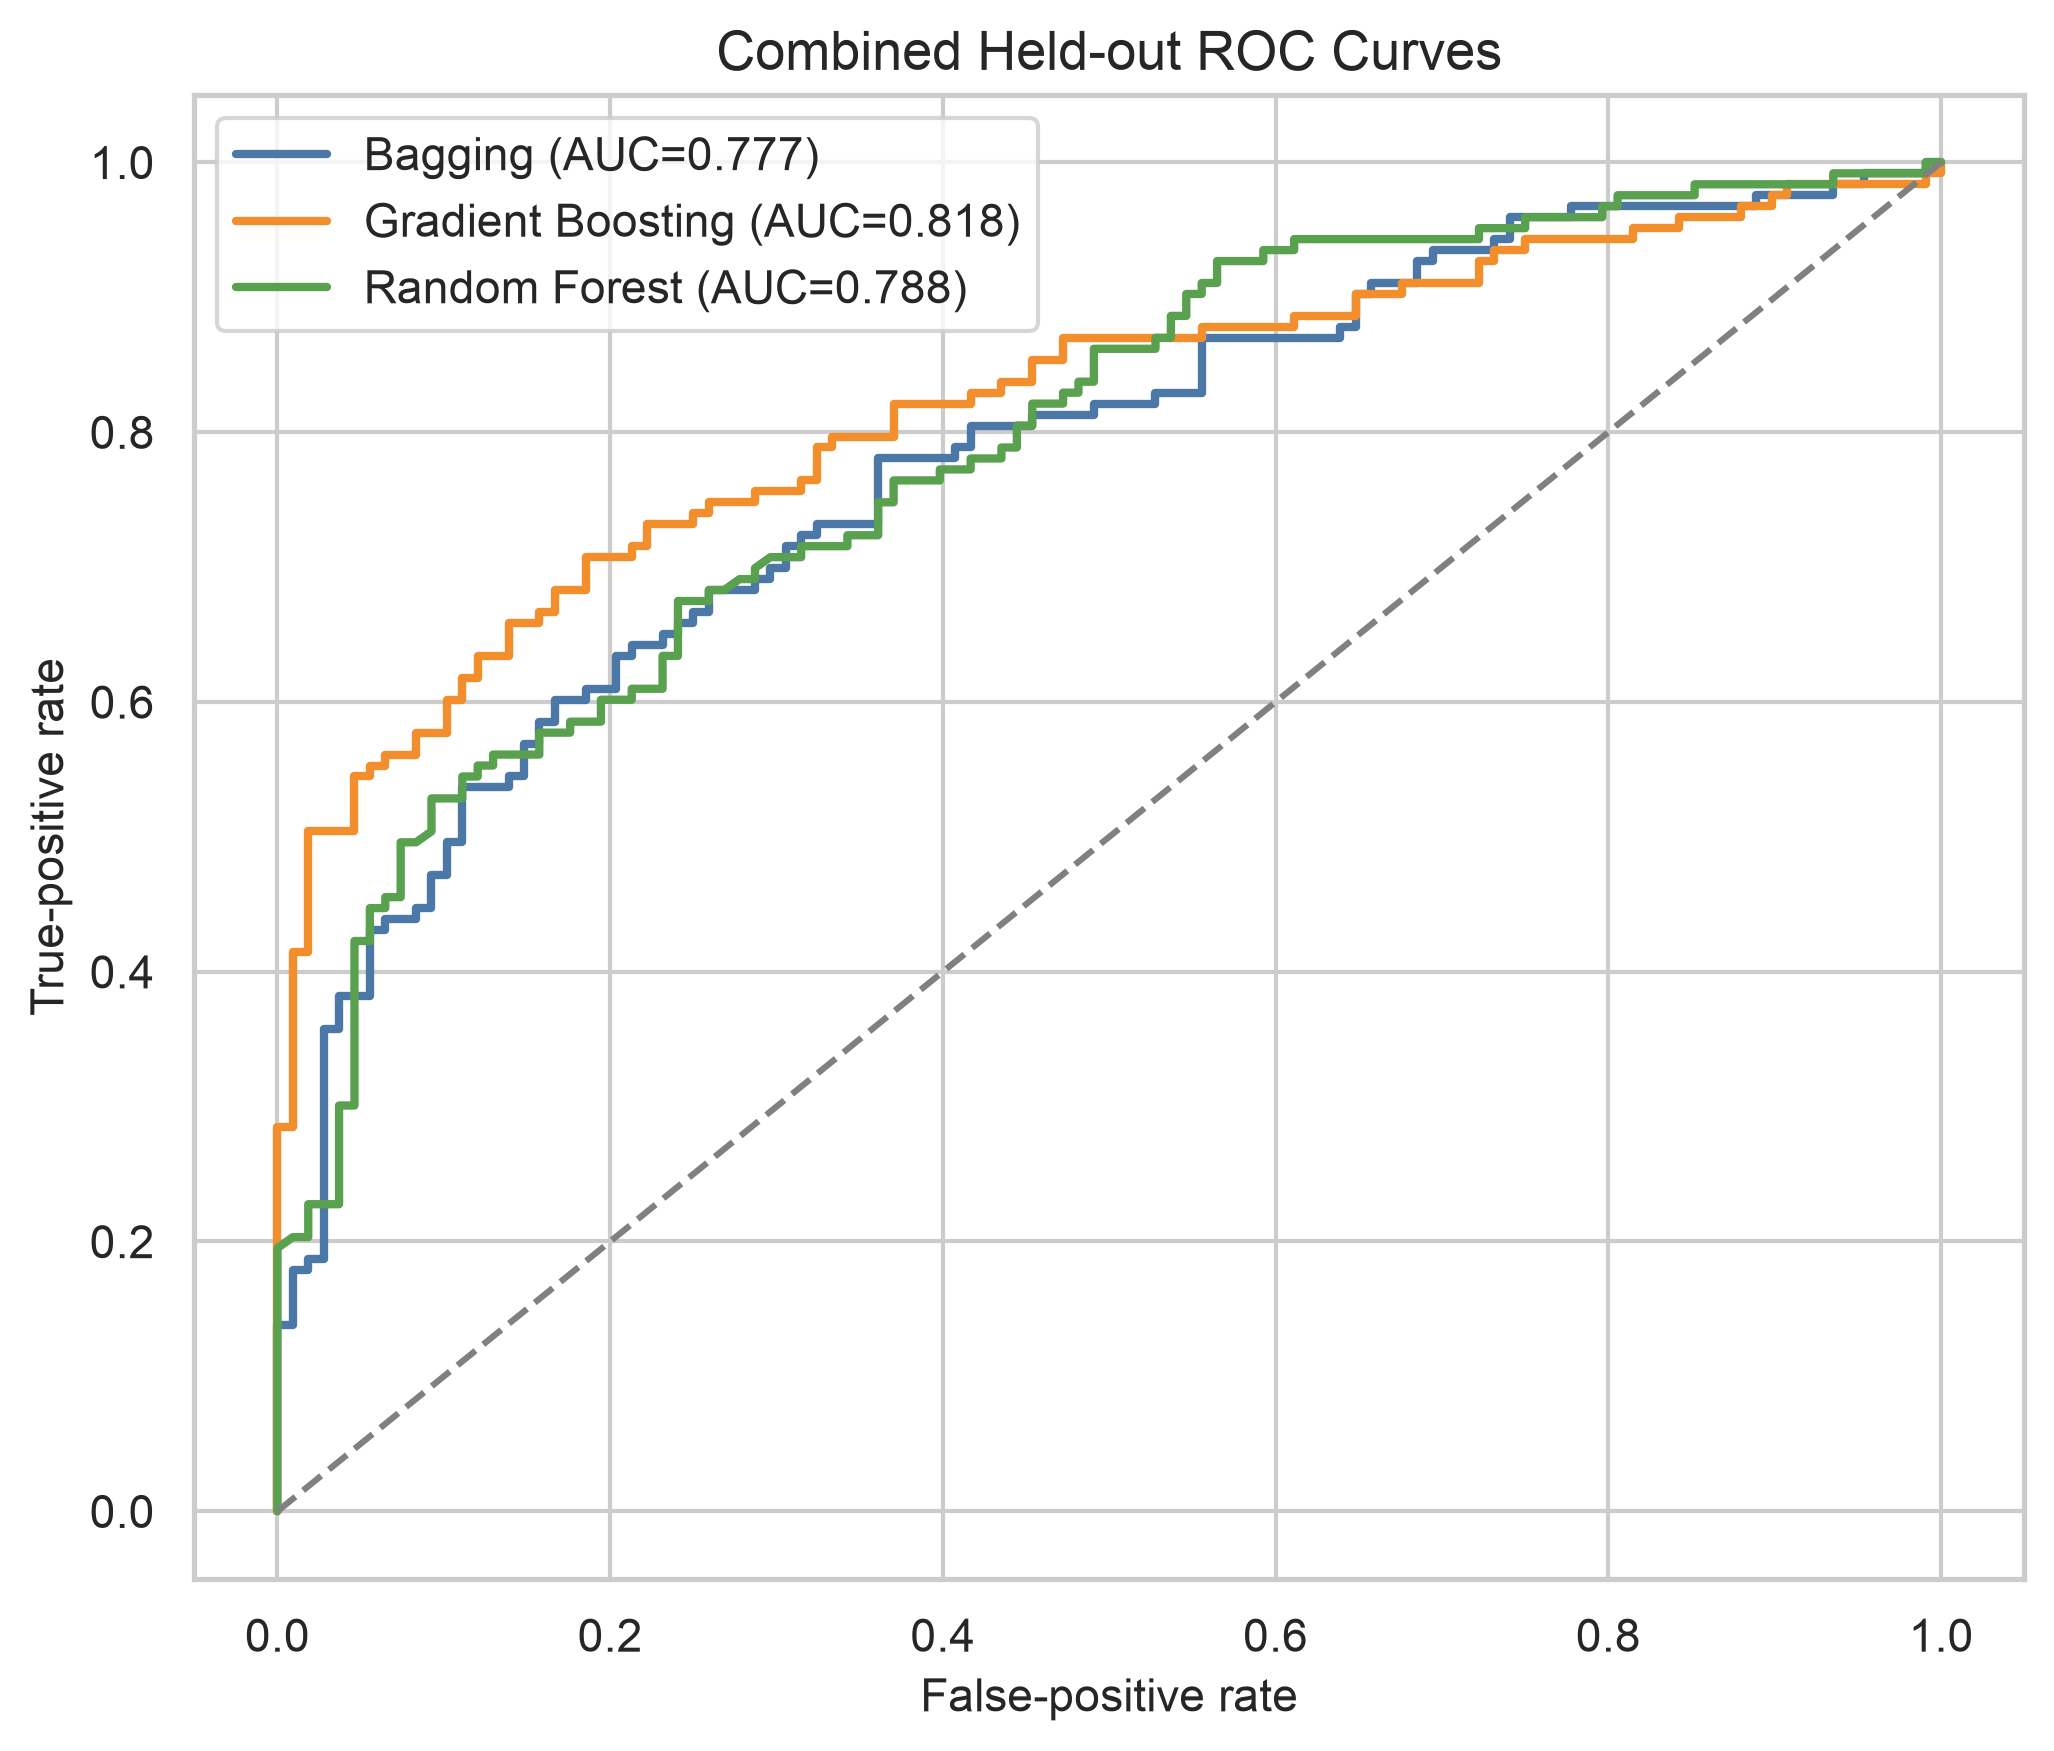

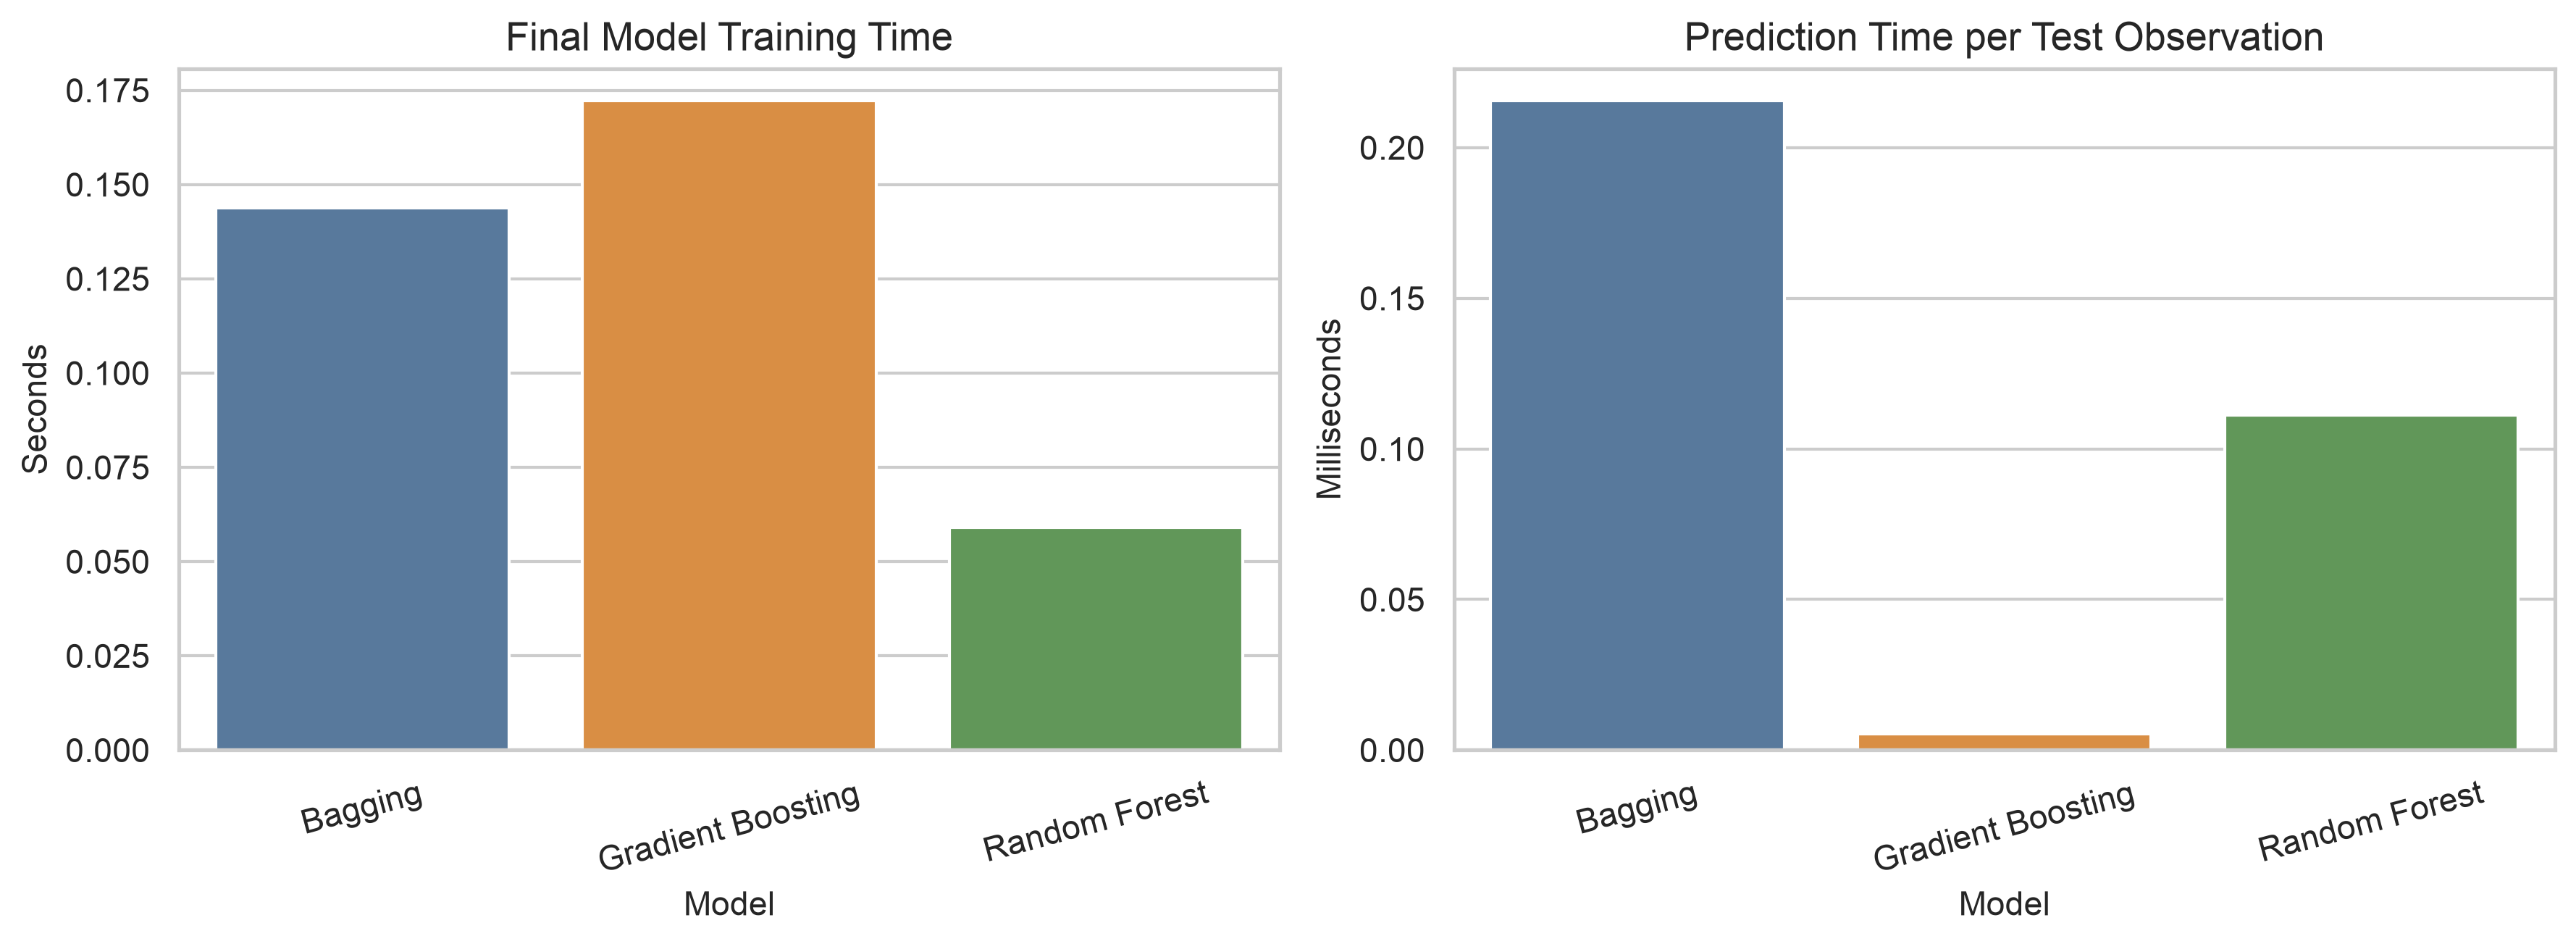

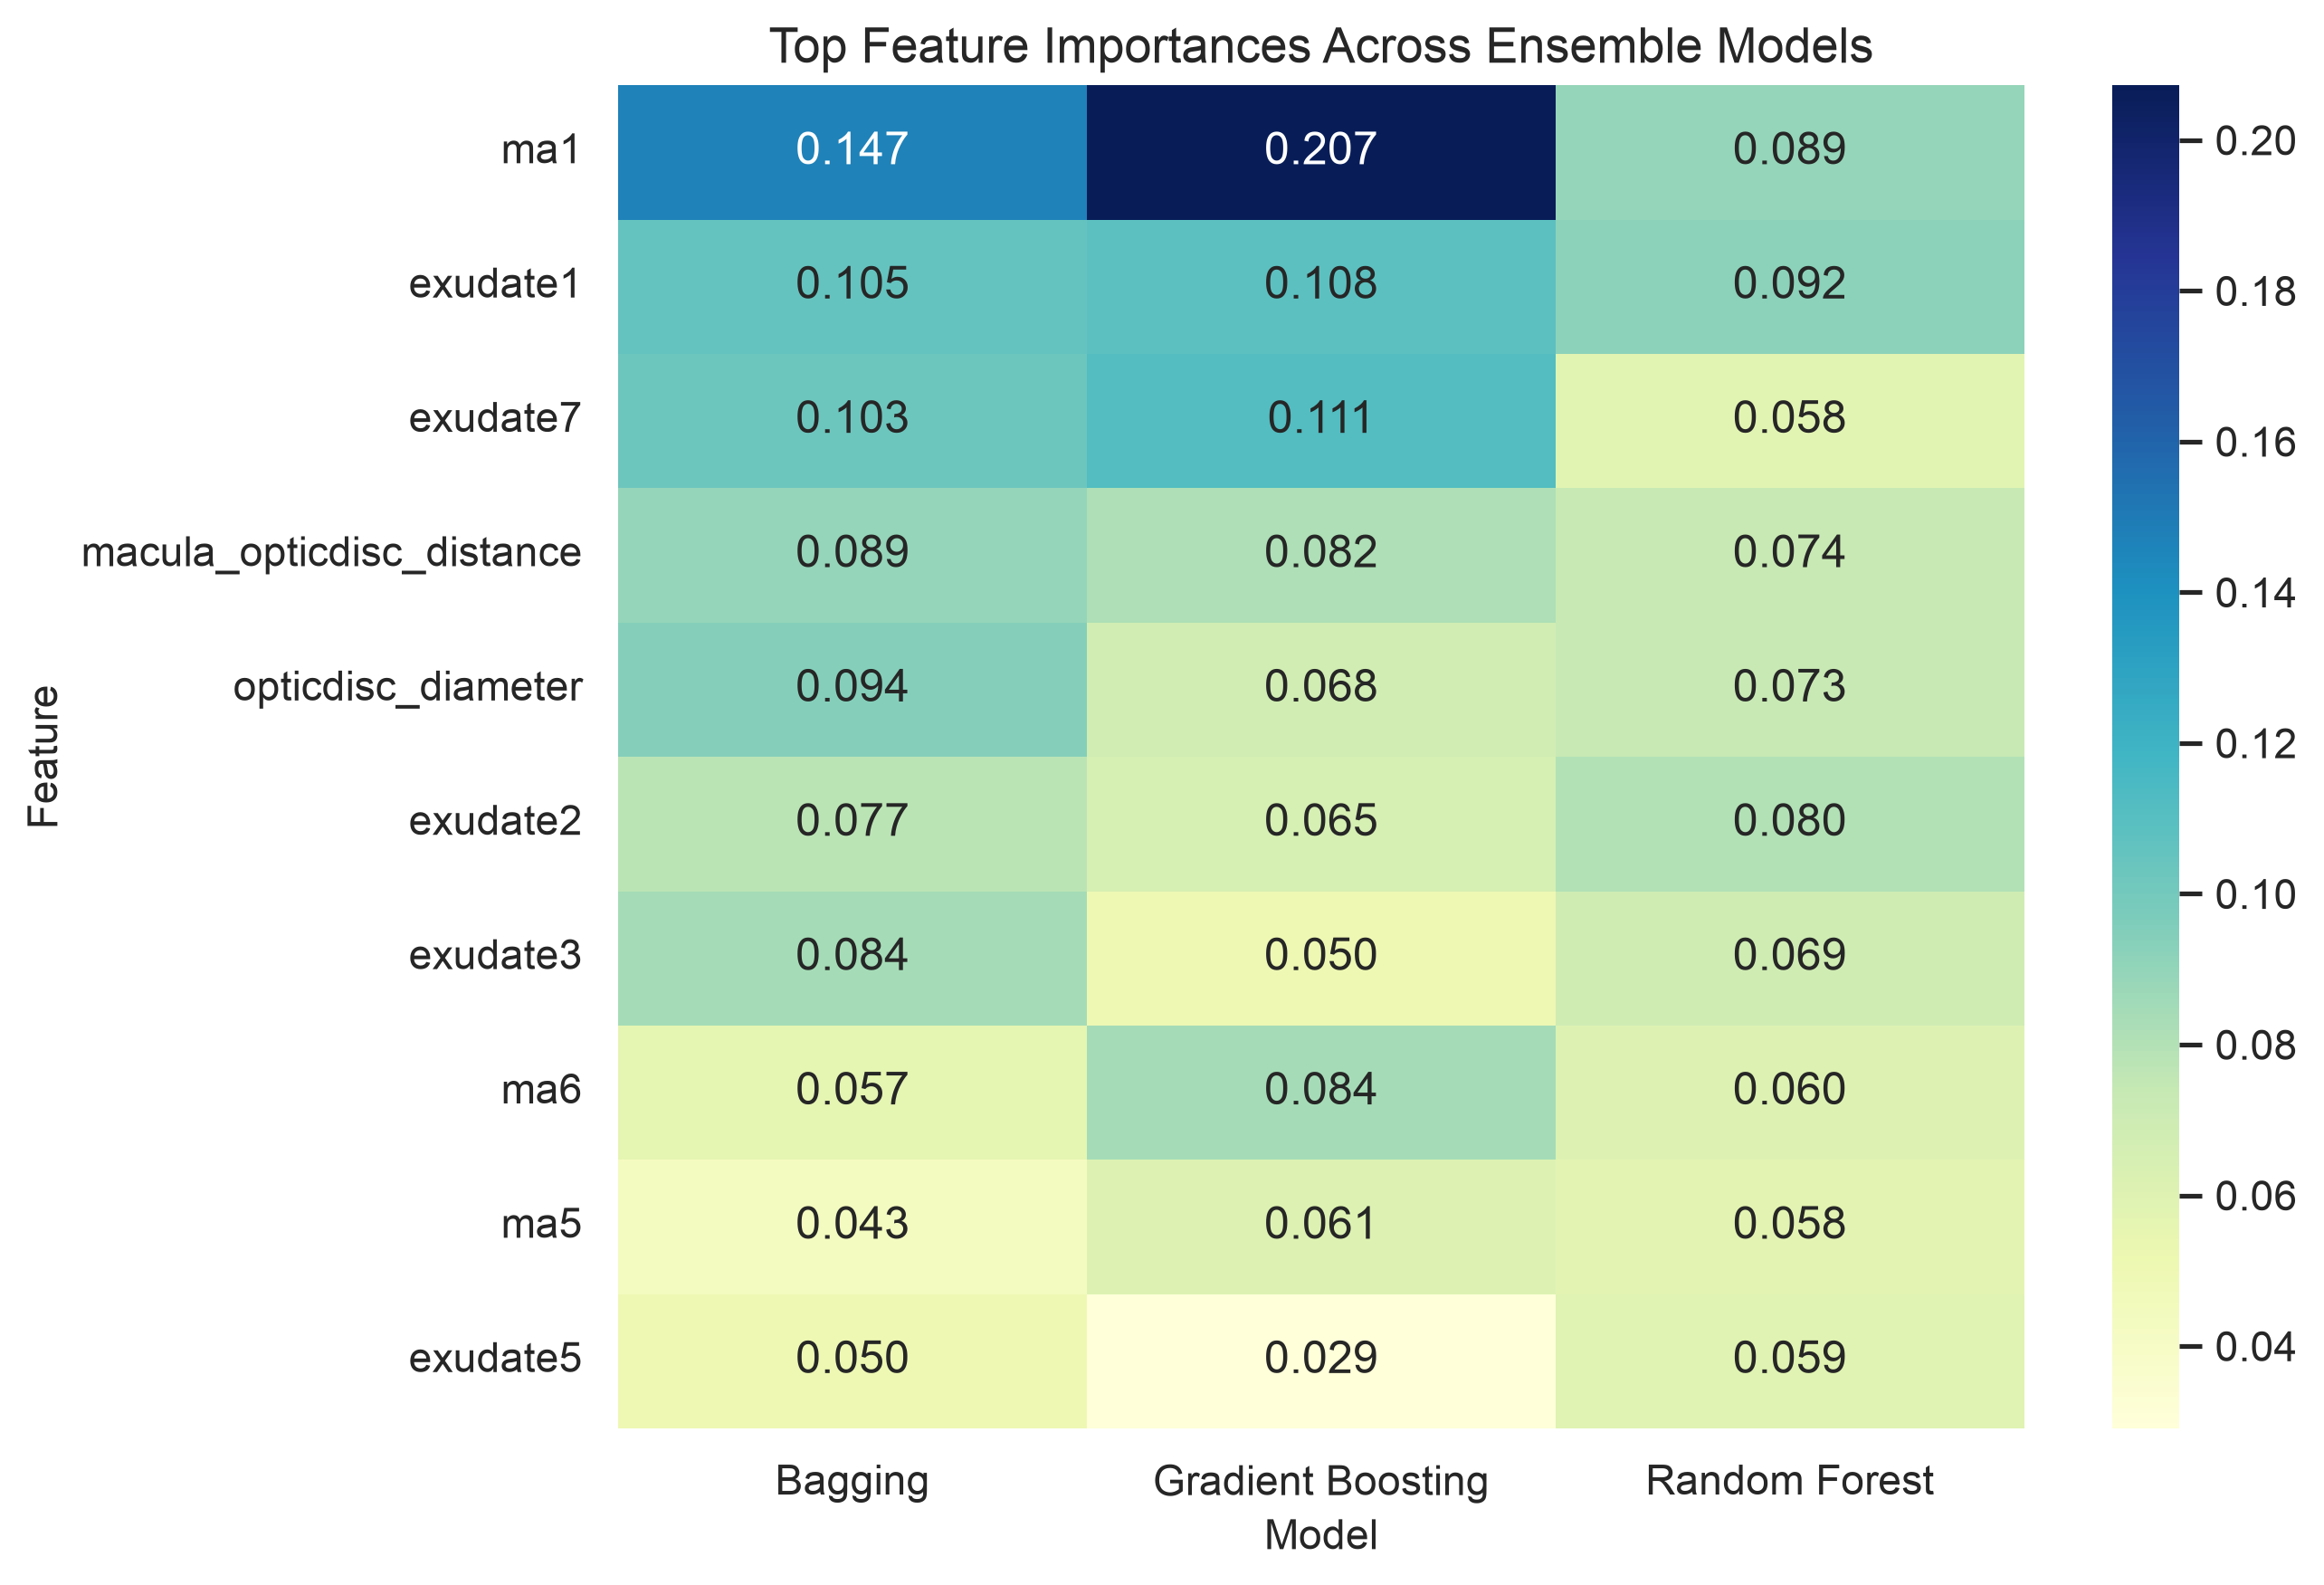

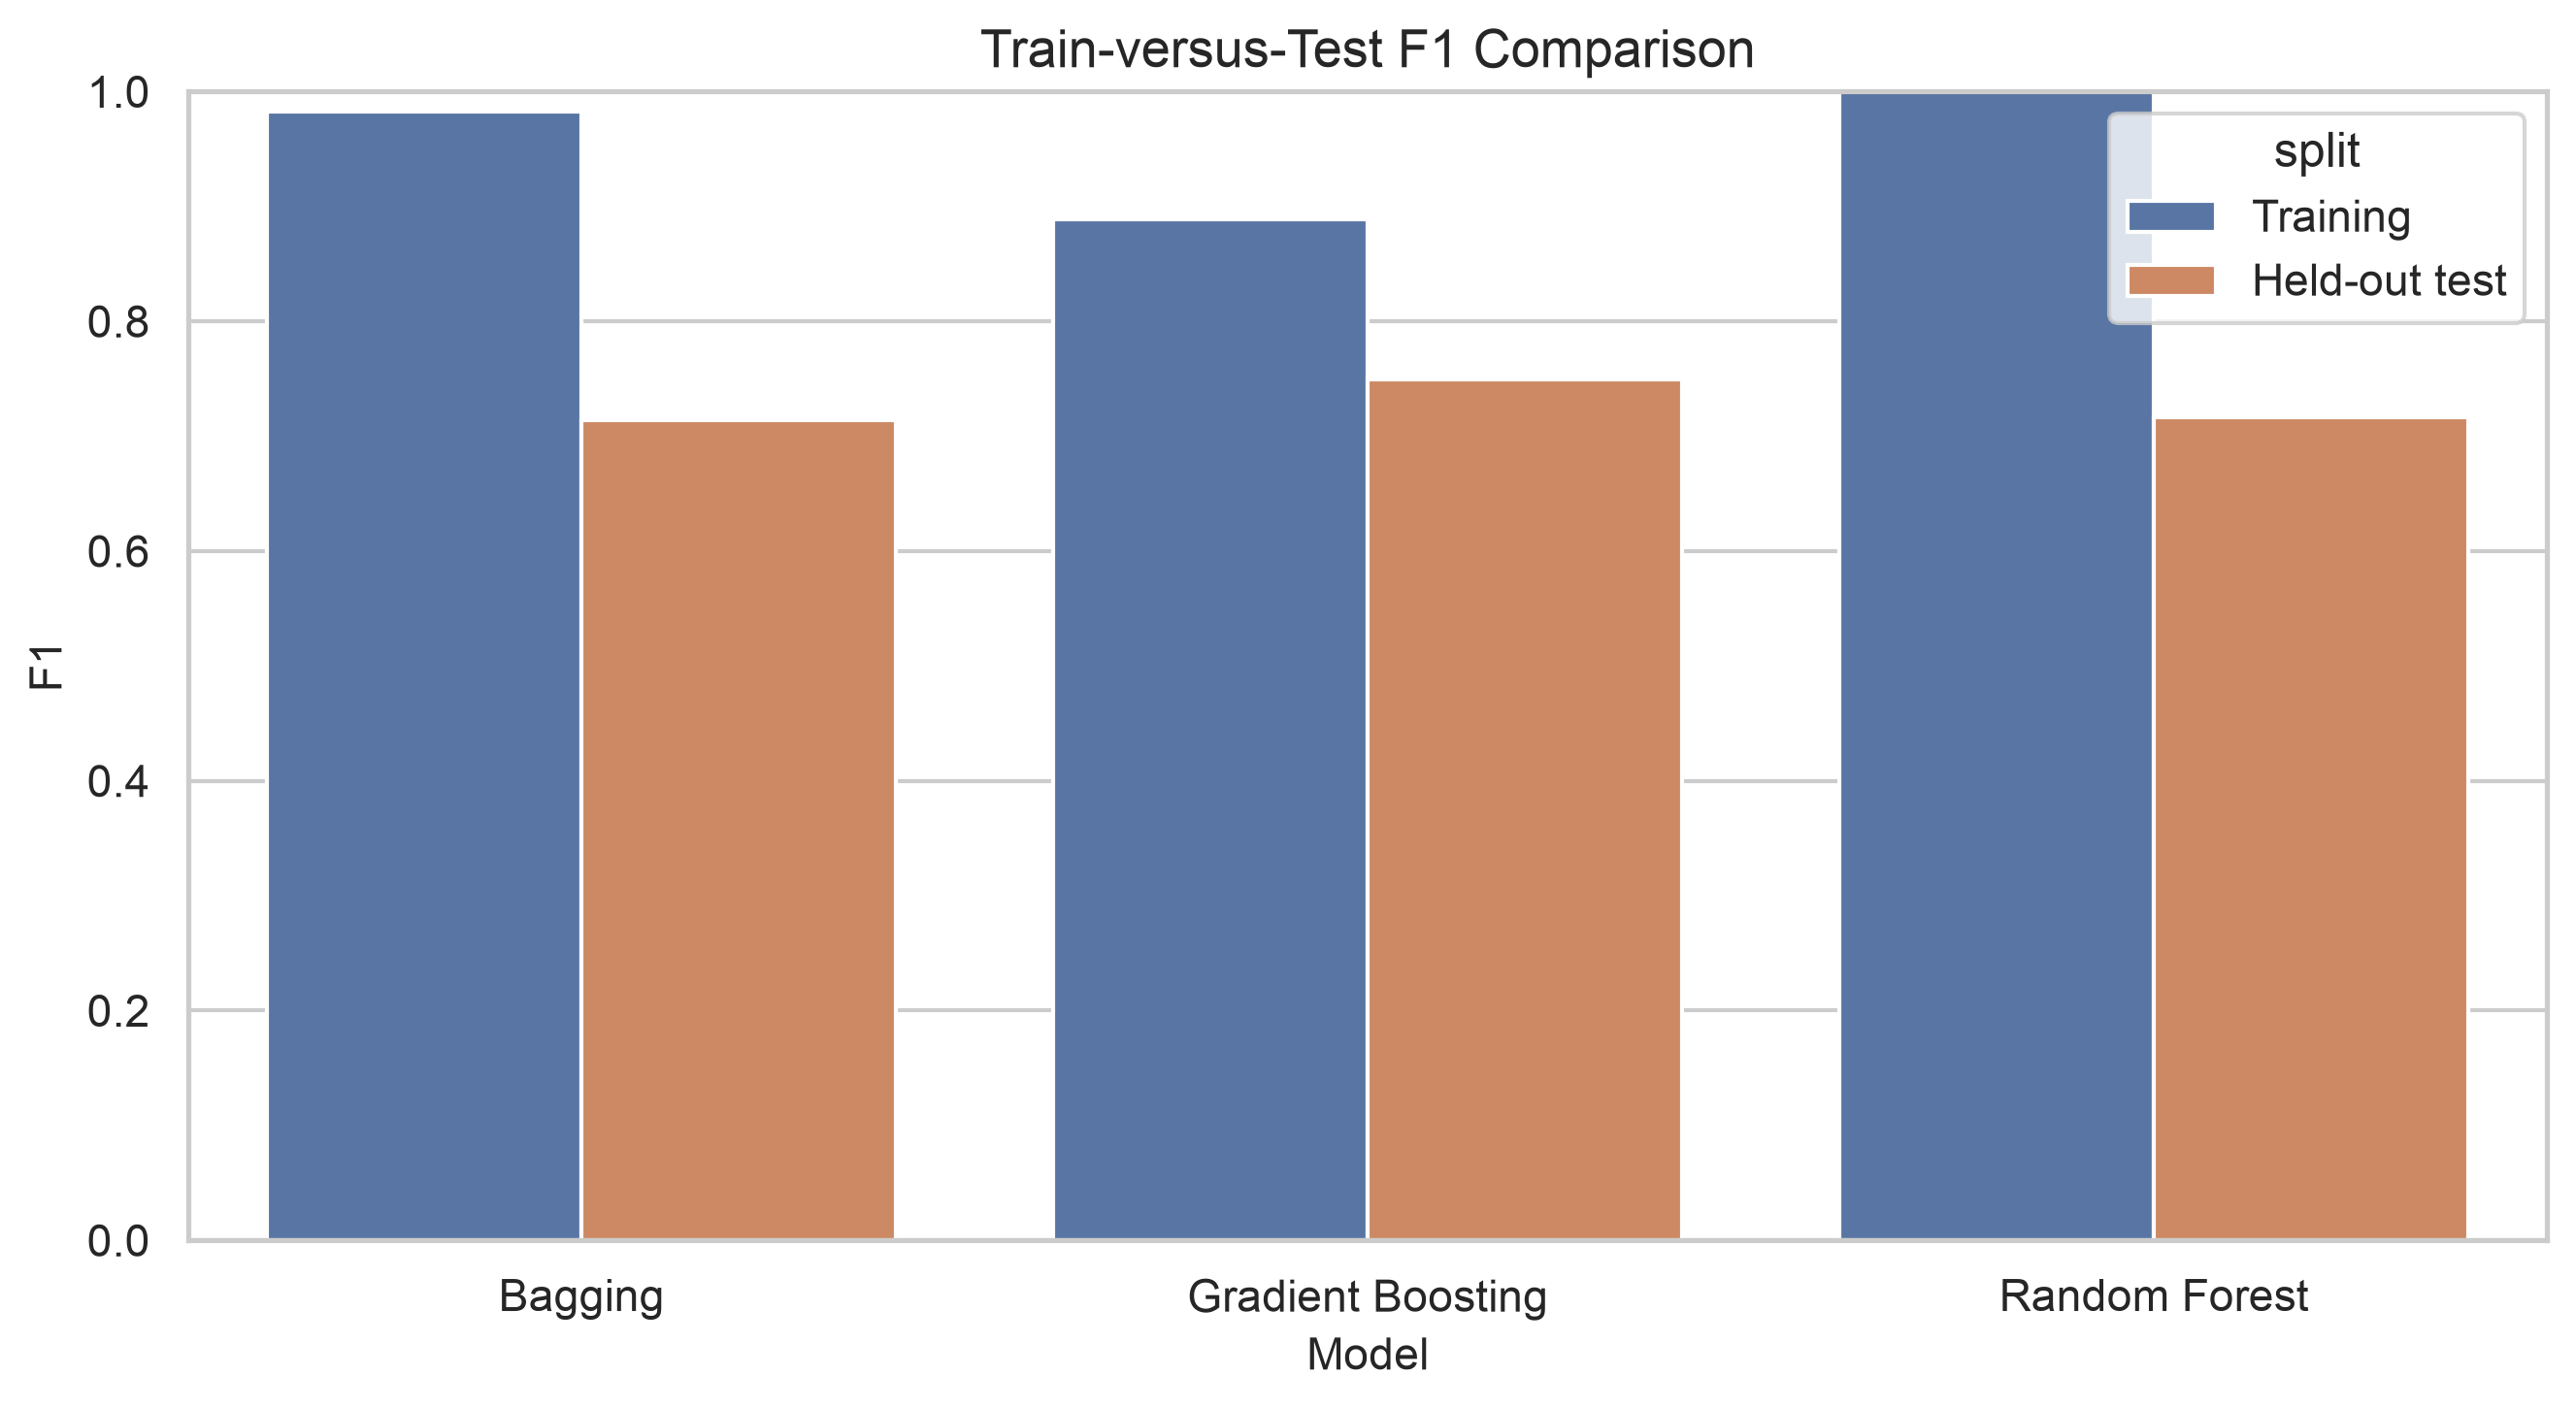

In [14]:
for name in [
    '03_combined_roc_curves.png', '05_computational_efficiency.png',
    '06_feature_importance_comparison.png', '07_train_test_comparison.png']:
    display(Image(filename=str(MODELS / name)))

## 13. Comparative Analysis

All models use the same 231 test observations. Gradient Boosting has the highest accuracy, sensitivity, F1, and ROC-AUC. Random Forest slightly improves F1 and ROC-AUC over ordinary Bagging, but both have high training performance and identical false-negative counts.

In [15]:
comparison = metrics.set_index('model')
display(comparison[['accuracy','recall_sensitivity','specificity','f1_score','roc_auc','training_time_seconds','prediction_time_ms_per_observation']].round(4))
print('Gradient Boosting false negatives:', int(comparison.loc['Gradient Boosting','false_negative']))
print('Bagging / Random Forest false negatives:', int(comparison.loc['Bagging','false_negative']), '/', int(comparison.loc['Random Forest','false_negative']))

,accuracy,recall_sensitivity,specificity,f1_score,roc_auc,training_time_seconds,prediction_time_ms_per_observation
model,,,,,,,
Bagging,0.7013,0.6992,0.7037,0.7137,0.7771,0.1437,0.2155
Gradient Boosting,0.7273,0.7642,0.6852,0.7490,0.8180,0.1721,0.0053
Random Forest,0.7056,0.6992,0.7130,0.7167,0.7885,0.0590,0.1112


Gradient Boosting false negatives: 29
Bagging / Random Forest false negatives: 37 / 37


## 14. Result Interpretation

- Gradient Boosting: accuracy 0.727, sensitivity 0.764, F1 0.749, ROC-AUC 0.818.
- Random Forest: F1 0.717 and ROC-AUC 0.788; a small improvement over Bagging.
- Bagging: F1 0.714 and ROC-AUC 0.777.
- Gradient Boosting has the lowest internal CV F1 standard deviation.
- No model establishes diagnostic or clinical validity.

In [16]:
print((RESULTS / 'results_interpretation.md').read_text())

# PBL-3 Results and Research Inferences

## Central research question

Which of Bagged Decision Trees, standard Gradient Boosting, and Random Forest provides the most effective and reliable prediction of the Debrecen DR label under the same split and evaluation protocol?

## Held-out results

model,accuracy,precision,recall_sensitivity,specificity,f1_score,roc_auc,training_time_seconds,prediction_time_ms_per_observation
Bagging,0.7012987012987013,0.7288135593220338,0.6991869918699187,0.7037037037037037,0.7136929460580913,0.7771002710027101,0.14370912499998667,0.21549729437136594
Gradient Boosting,0.7272727272727273,0.734375,0.7642276422764228,0.6851851851851852,0.749003984063745,0.8179765130984643,0.17214058399986243,0.005270199132858331
Random Forest,0.7056277056277056,0.7350427350427351,0.6991869918699187,0.7129629629629629,0.7166666666666667,0.7884673291177356,0.059032540999851335,0.111175683983887


## Evidence-based answers

- Highest held-out accuracy: **Gradient Boosting** (0.72

## 15. Conclusion

Under this shared protocol, standard Gradient Boosting provides the best observed balance of predictive quality and positive-class detection. Random feature selection gives Random Forest only a modest advantage over ordinary Bagging. Evaluation must consider sensitivity, specificity, discrimination, stability, generalization gap, and computation—not accuracy alone.

### Limitations

One small dataset, no raw images or demographics, five duplicate rows, one grouped holdout, no external cohort, machine-specific timings, and model-dependent importance.

### Source

UCI Machine Learning Repository: Diabetic Retinopathy Debrecen Data Set, Antal & Hajdu (2014). Accessed 16 November 2026.

In [17]:
print('Notebook execution complete.')
print('Stored result files:', len(list(RESULTS.glob('*'))))
print('Stored 300-DPI figures:', len(list(EDA.glob('*.png'))) + len(list(MODELS.glob('*.png'))))

Notebook execution complete.
Stored result files: 18
Stored 300-DPI figures: 15
